# Лабораторная работа №15: Flow matching и rectified flow

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать 2D rectified flow.
- Визуализировать vector field и trajectories.
- Сравнить Euler steps и diffusion baseline.

## Теоретическая часть

Flow matching обучает vector field $v_\theta(x_t,t)$, переносящий простое распределение в data distribution. Для rectified path $x_t=(1-t)x_0+tx_1$ target velocity равна $x_1-x_0$. Sampling решает ODE.

![Flow matching paths](https://raw.githubusercontent.com/atong01/conditional-flow-matching/main/assets/cfm.png)


Rectified flow строит линейный путь x_t=(1−t)x₀+tx₁ с полем v*=x₁−x₀; интегрирование ODE Euler переносит шум к данным. На двумерном распределении можно оценить покрытие мод и нарисовать траектории; VP diffusion служит отдельно обучаемой контрольной моделью при том же бюджете.

Для VP-пути $x_t=\cos(\pi t/2)x_1+\sin(\pi t/2)\epsilon$. В предельной точке $t=1$ восстановление $x_1$ через деление на $\alpha_t$ не определено: в коде используется явно ограниченное $t\leq0.9$ как приближение шумового старта.

### Экспериментальный протокол

Демонстрационная задача — восьмимодальное 2D распределение, а не MNIST. Полный режим обучает две отдельные модели по 3000 шагов и coupling ablation; smoke — 3 шага, его картинки/метрики не используются в выводах. Все числовые метрики рассчитываются из фактических точек относительно test.

### Материалы

- [Conditional Flow Matching](https://github.com/atong01/conditional-flow-matching)
- [Flow Matching paper](https://arxiv.org/abs/2210.02747)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch

SEED = 42
FAST_DEV_RUN = False  # True: только проверка связности, не для сдачи

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# У каждой лабы своя папка: artifacts/lab15 — метрики, таблицы, рисунки, checkpoints;
# data/lab15 — сгенерированные train/test выборки восьмимодального 2D распределения.
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab15'))
DATA_ROOT = Path(os.getenv('CV_DATA', 'data/lab15'))
CKPT_DIR = ARTIFACTS / 'checkpoints'
FIG_DIR = ARTIFACTS / 'figures'
for folder in (ARTIFACTS, DATA_ROOT, CKPT_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
NOTEBOOK_T0 = time.time()  # начало прогона — для итогового run_info.json

def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(value, ensure_ascii=False, indent=2, default=str)
    destination.write_text(text, encoding='utf-8')

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN, 'artifacts': str(ARTIFACTS),
       'data': str(DATA_ROOT), 'checkpoints': str(CKPT_DIR), 'figures': str(FIG_DIR)})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts\\lab15', 'data': 'data\\lab15', 'checkpoints': 'artifacts\\lab15\\checkpoints', 'figures': 'artifacts\\lab15\\figures'}


### Задание 1. Геометрия восьмимодального распределения

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте независимые train/test выборки с фиксированными seed и центрами мод.

**Результат.** Проверяемое состояние «Геометрия восьмимодального распределения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте независимые train/test выборки с фиксированными seed и центрами мод» и его результат доступен следующему этапу.

**Задание 1. Геометрия восьмимодального распределения**

- **Что делали**: сгенерировали 8 гауссовых мод на окружности радиуса 4 (std 0.3): train 20 000 точек (seed 42) и test 5 000 точек (seed 1042) — два независимых генератора.
- **Зачем**: получить данные, на которых геометрию распределения и траекторий можно измерить напрямую; test нужен как независимый эталон для оценки сэмплов.
- **Результат**: `data/lab15/eight_modes.npz`, `data_geometry.json`, `figures/data_geometry.png`. По 2500 (train) и 625 (test) точек на моду, общих точек 0, метка = ближайший центр у 100% точек, сдвиг эмпирического центра ≤ 0.025, соседние моды разнесены на 3.06 ≈ 10 std.

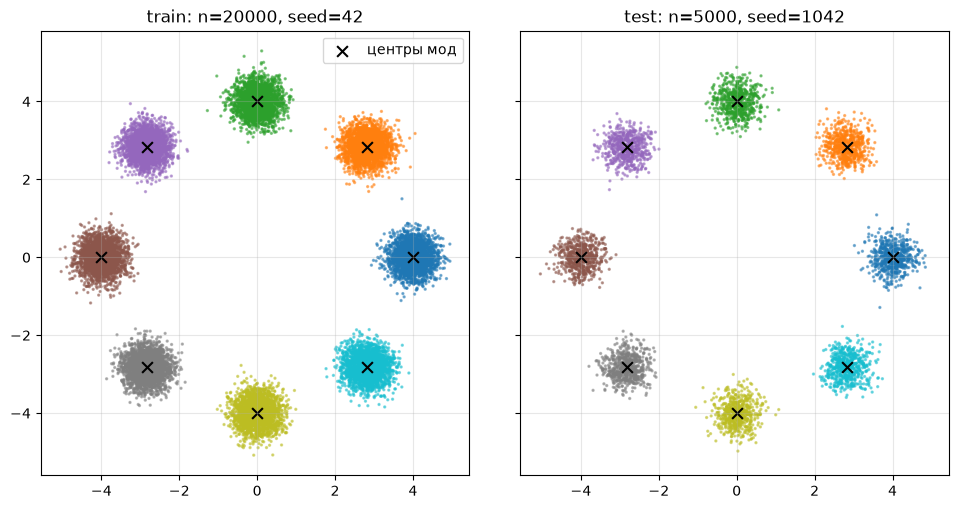

{'n_modes': 8, 'radius': 4.0, 'mode_std': 0.3, 'min_center_gap': 3.061467409133911, 'gap_in_std': 10.204891363779705, 'shared_train_test_points': 0}
train {'n': 20000, 'label_matches_nearest_center': 1.0, 'mean_dist_to_center': 0.376, 'counts': [2500, 2500, 2500, 2500, 2500, 2500, 2500, 2500], 'max_center_error': 0.0106}
test {'n': 5000, 'label_matches_nearest_center': 1.0, 'mean_dist_to_center': 0.377, 'counts': [625, 625, 625, 625, 625, 625, 625, 625], 'max_center_error': 0.0247}


In [2]:
# Задание 1. Восемь гауссовых мод на окружности; train и test — независимые генераторы с разными seed.
import matplotlib.pyplot as plt

N_MODES = 8
RADIUS = 4.0      # радиус окружности центров мод
MODE_STD = 0.3    # изотропное std каждой моды; моды разнесены на 2R·sin(π/8) ≈ 3.06 ≈ 10 std
N_TRAIN = 512 if FAST_DEV_RUN else 20000
N_TEST = 256 if FAST_DEV_RUN else 5000
TRAIN_SEED, TEST_SEED = SEED, SEED + 1000

ANGLES = 2 * np.pi * np.arange(N_MODES) / N_MODES
CENTERS = np.stack([RADIUS * np.cos(ANGLES), RADIUS * np.sin(ANGLES)], axis=1).astype(np.float32)

def sample_eight_modes(n, seed):
    """Сбалансированная выборка: метки ровно поровну (с точностью до остатка), порядок перемешан."""
    rng = np.random.default_rng(seed)
    labels = rng.permutation(np.arange(n) % N_MODES)
    points = CENTERS[labels] + MODE_STD * rng.standard_normal((n, 2)).astype(np.float32)
    return points.astype(np.float32), labels.astype(np.int64)

def assign_modes(points):
    """Ближайший центр и расстояние до него — общая разметка для оценки покрытия мод (задание 7)."""
    d = np.linalg.norm(np.asarray(points)[:, None, :] - CENTERS[None], axis=-1)
    return d.argmin(1), d.min(1)

X_train, y_train = sample_eight_modes(N_TRAIN, TRAIN_SEED)
X_test, y_test = sample_eight_modes(N_TEST, TEST_SEED)
np.savez(DATA_ROOT / 'eight_modes.npz', X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
         centers=CENTERS, mode_std=MODE_STD, train_seed=TRAIN_SEED, test_seed=TEST_SEED)

# Проверки геометрии: метка совпадает с ближайшим центром, эмпирические центры/std близки к заданным,
# train и test не содержат общих точек.
def geometry_stats(points, labels):
    nearest, dist = assign_modes(points)
    per_mode = []
    for k in range(N_MODES):
        pts = points[labels == k]
        per_mode.append({'mode': k, 'count': int(len(pts)),
                         'center_error': float(np.linalg.norm(pts.mean(0) - CENTERS[k])),
                         'std_xy': [float(s) for s in pts.std(0)]})
    return {'n': int(len(points)), 'label_matches_nearest_center': float((nearest == labels).mean()),
            'mean_dist_to_center': float(dist.mean()), 'max_dist_to_center': float(dist.max()),
            'mean_norm': float(np.linalg.norm(points, axis=1).mean()), 'per_mode': per_mode}

train_rows = {tuple(r) for r in X_train.round(6).tolist()}
shared_points = sum(tuple(r) in train_rows for r in X_test.round(6).tolist())
min_center_gap = float(min(np.linalg.norm(CENTERS[i] - CENTERS[j])
                           for i in range(N_MODES) for j in range(i + 1, N_MODES)))
geometry = {'n_modes': N_MODES, 'radius': RADIUS, 'mode_std': MODE_STD,
            'min_center_gap': min_center_gap, 'gap_in_std': min_center_gap / MODE_STD,
            'train_seed': TRAIN_SEED, 'test_seed': TEST_SEED, 'shared_train_test_points': int(shared_points),
            'centers': CENTERS.tolist(), 'data_file': str(DATA_ROOT / 'eight_modes.npz'),
            'train': geometry_stats(X_train, y_train), 'test': geometry_stats(X_test, y_test)}
save_json('data_geometry.json', geometry)
assert shared_points == 0 and geometry['test']['label_matches_nearest_center'] > 0.99

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, (name, pts, lab) in zip(axes, [('train', X_train, y_train), ('test', X_test, y_test)]):
    ax.scatter(pts[:, 0], pts[:, 1], c=lab, cmap='tab10', s=2, alpha=0.5)
    ax.scatter(CENTERS[:, 0], CENTERS[:, 1], c='black', marker='x', s=60, label='центры мод')
    ax.set_title(f'{name}: n={len(pts)}, seed={TRAIN_SEED if name == "train" else TEST_SEED}')
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
axes[0].legend(loc='upper right')
fig.tight_layout(); fig.savefig(FIG_DIR / 'data_geometry.png', dpi=120); plt.show()

print({k: geometry[k] for k in ('n_modes', 'radius', 'mode_std', 'min_center_gap', 'gap_in_std',
                                'shared_train_test_points')})
for split in ('train', 'test'):
    g = geometry[split]
    print(split, {'n': g['n'], 'label_matches_nearest_center': round(g['label_matches_nearest_center'], 4),
                  'mean_dist_to_center': round(g['mean_dist_to_center'], 3),
                  'counts': [m['count'] for m in g['per_mode']],
                  'max_center_error': round(max(m['center_error'] for m in g['per_mode']), 4)})

### Задание 2. Векторное поле и линейный путь

*Вес: 1 балл.*

**Постановка.** На простой двумерной задаче можно непосредственно измерить геометрию распределений и траекторий. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите MLP и визуализируйте линейный путь между шумом и реальными точками.

**Результат.** Проверяемое состояние «Векторное поле и линейный путь» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите MLP и визуализируйте линейный путь между шумом и реальными точками» и его результат доступен следующему этапу.

**Задание 2. Векторное поле и линейный путь**

- **Что делали**: определили `TimeMLP` (вход (x, y) + Фурье-признаки t на 8 частотах, 4 слоя по 256, SiLU) и функцию `linear_path`: x_t = (1 − t)·x0 + t·x1 с целевой скоростью x1 − x0; нарисовали пути шум → данные.
- **Зачем**: это поле v_θ(x, t), которое будет учить flow; проверить до обучения, что путь прямой и задан правильно.
- **Результат**: `flow_architecture.json`, `linear_path.json`, `figures/linear_path.png`, `checkpoints/flow_init.pt`. 203 010 параметров; ошибки на концах и в середине пути 0.0; длина целевой скорости 4.10 ± 1.03; средний радиус вдоль пути 1.26 → 1.34 → 2.08 → 3.02 → 4.01; MSE необученной сети при t = 0.5 — 8.95.

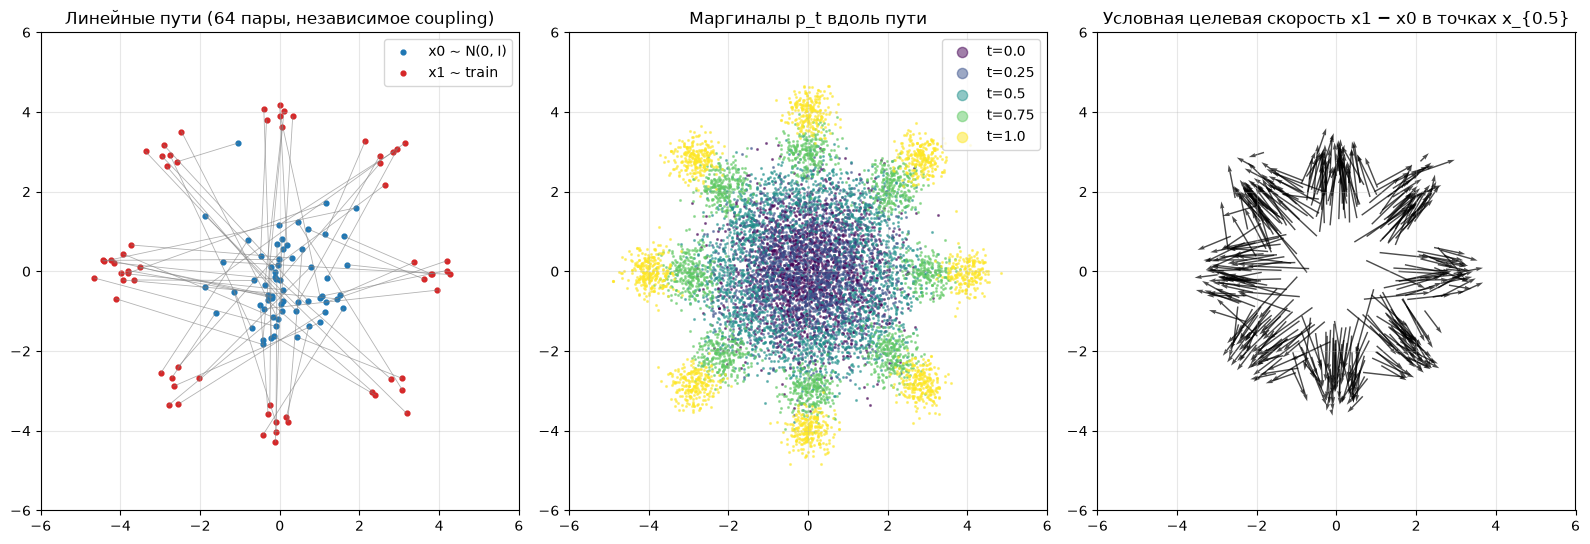

TimeMLP(
  (net): Sequential(
    (0): Linear(in_features=19, out_features=256, bias=True)
    (1): SiLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): SiLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): SiLU()
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): SiLU()
    (8): Linear(in_features=256, out_features=2, bias=True)
  )
)
{'n_params': 203010, 'endpoint_error_t0': 0.0, 'endpoint_error_t1': 0.0, 'midpoint_error': 0.0, 'target_speed_mean': 4.102906, 'target_speed_std': 1.02688, 'untrained_mse_at_t0.5': 8.953}
{'0.0': 1.257, '0.25': 1.343, '0.5': 2.083, '0.75': 3.023, '1.0': 4.006}


In [3]:
# Задание 2. MLP-поле v_θ(x, t) и линейный (rectified) путь x_t = (1 − t)·x0 + t·x1, x0 ~ N(0, I), x1 ~ data.
import torch.nn as nn

HIDDEN = 256
N_LAYERS = 4          # число скрытых линейных слоёв
N_FREQ = 8            # частоты Фурье-признаков времени
MODEL_SEED = SEED     # одинаковая инициализация для всех моделей одной архитектуры

class TimeMLP(nn.Module):
    """MLP по (x, t): t кодируется Фурье-признаками и конкатенируется с координатами точки."""
    def __init__(self, dim=2, hidden=HIDDEN, n_layers=N_LAYERS, n_freq=N_FREQ):
        super().__init__()
        # частоты π·2^k, k = −2…n_freq−3: от медленных (0.25π) до быстрых изменений поля по t
        self.register_buffer('freqs', torch.pi * 2.0 ** torch.arange(-2, n_freq - 2, dtype=torch.float32))
        layers, width = [], dim + 1 + 2 * n_freq
        for _ in range(n_layers):
            layers += [nn.Linear(width, hidden), nn.SiLU()]
            width = hidden
        layers.append(nn.Linear(width, dim))
        self.net = nn.Sequential(*layers)

    def time_features(self, t):
        t = t.reshape(-1, 1)
        angles = t * self.freqs
        return torch.cat([t, torch.sin(angles), torch.cos(angles)], dim=1)

    def forward(self, x, t):
        t = torch.as_tensor(t, dtype=x.dtype, device=x.device)
        if t.ndim == 0:  # одно t на весь батч
            t = t.expand(x.shape[0])
        return self.net(torch.cat([x, self.time_features(t)], dim=1))

def make_mlp(seed=MODEL_SEED):
    torch.manual_seed(seed)
    return TimeMLP().to(DEVICE)

def linear_path(x0, x1, t):
    """Точка на прямом пути и целевая скорость rectified flow; t формы (B,)."""
    t = t.reshape(-1, 1)
    return (1 - t) * x0 + t * x1, x1 - x0

X_train_t = torch.from_numpy(X_train).to(DEVICE)
X_test_t = torch.from_numpy(X_test).to(DEVICE)
flow_model = make_mlp()
n_params = sum(p.numel() for p in flow_model.parameters())
torch.save(flow_model.state_dict(), CKPT_DIR / 'flow_init.pt')

# Независимое coupling: случайный шум в паре со случайными train-точками (фиксированный генератор).
gen = torch.Generator().manual_seed(SEED + 2)
N_VIS = 2048
x1_vis = X_train_t[torch.randint(len(X_train_t), (N_VIS,), generator=gen).to(DEVICE)]
x0_vis = torch.randn(N_VIS, 2, generator=gen).to(DEVICE)
T_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]

path_checks = {}
with torch.no_grad():
    xt0, v = linear_path(x0_vis, x1_vis, torch.zeros(N_VIS, device=DEVICE))
    xt1, _ = linear_path(x0_vis, x1_vis, torch.ones(N_VIS, device=DEVICE))
    xt_mid, _ = linear_path(x0_vis, x1_vis, torch.full((N_VIS,), 0.5, device=DEVICE))
    # Прямолинейность: точка в t=0.5 лежит ровно посередине отрезка, |dx/dt| постоянна и равна |x1 − x0|.
    path_checks = {
        'endpoint_error_t0': float((xt0 - x0_vis).abs().max()),
        'endpoint_error_t1': float((xt1 - x1_vis).abs().max()),
        'midpoint_error': float((xt_mid - 0.5 * (x0_vis + x1_vis)).abs().max()),
        'target_speed_mean': float(v.norm(dim=1).mean()),
        'target_speed_std': float(v.norm(dim=1).std()),
    }
    marginal_stats = {}
    for t in T_GRID:
        xt, _ = linear_path(x0_vis, x1_vis, torch.full((N_VIS,), t, device=DEVICE))
        marginal_stats[str(t)] = {'mean': xt.mean(0).tolist(), 'std': xt.std(0).tolist(),
                                  'mean_radius': float(xt.norm(dim=1).mean())}
    # Необученное поле: проверка формы выхода и масштаба до обучения.
    v_init = flow_model(xt_mid, torch.full((N_VIS,), 0.5, device=DEVICE))
    init_mse = float(((v_init - v) ** 2).mean())
assert v_init.shape == (N_VIS, 2) and path_checks['midpoint_error'] < 1e-5

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
x0n, x1n = x0_vis.cpu().numpy(), x1_vis.cpu().numpy()
ax = axes[0]
for i in range(64):
    ax.plot([x0n[i, 0], x1n[i, 0]], [x0n[i, 1], x1n[i, 1]], color='gray', lw=0.6, alpha=0.6)
ax.scatter(x0n[:64, 0], x0n[:64, 1], s=12, c='tab:blue', label='x0 ~ N(0, I)')
ax.scatter(x1n[:64, 0], x1n[:64, 1], s=12, c='tab:red', label='x1 ~ train')
ax.set_title('Линейные пути (64 пары, независимое coupling)'); ax.legend(loc='upper right')
ax = axes[1]
cmap = plt.get_cmap('viridis')
for t in T_GRID:
    xt = (1 - t) * x0n + t * x1n
    ax.scatter(xt[:, 0], xt[:, 1], s=1.5, alpha=0.5, color=cmap(t), label=f't={t}')
ax.set_title('Маргиналы p_t вдоль пути'); ax.legend(loc='upper right', markerscale=6)
ax = axes[2]
xm, vn = xt_mid.cpu().numpy()[:400], v.cpu().numpy()[:400]
ax.quiver(xm[:, 0], xm[:, 1], vn[:, 0], vn[:, 1], angles='xy', scale_units='xy', scale=4, width=0.003, alpha=0.7)
ax.set_title('Условная целевая скорость x1 − x0 в точках x_{0.5}')
for ax in axes:
    ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
fig.tight_layout(); fig.savefig(FIG_DIR / 'linear_path.png', dpi=120); plt.show()

architecture = {'class': 'TimeMLP', 'hidden': HIDDEN, 'n_layers': N_LAYERS, 'n_freq': N_FREQ,
                'activation': 'SiLU', 'input': '(x, y) + [t, sin, cos]-Фурье-признаки t', 'output': 'velocity (2,)',
                'n_params': int(n_params), 'init_seed': MODEL_SEED, 'init_checkpoint': str(CKPT_DIR / 'flow_init.pt')}
save_json('flow_architecture.json', architecture)
save_json('linear_path.json', {'n_pairs': N_VIS, 'coupling': 'independent', 'pair_seed': SEED + 2,
                               'checks': path_checks, 'marginals': marginal_stats,
                               'untrained_mse_at_t0.5': init_mse})
print(flow_model)
print({'n_params': n_params, **{k: round(v_, 6) for k, v_ in path_checks.items()},
       'untrained_mse_at_t0.5': round(init_mse, 3)})
print({t: round(s['mean_radius'], 3) for t, s in marginal_stats.items()})

### Задание 3. Вторая модель для VP diffusion

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную модель и два независимых оптимизатора.

**Результат.** Проверяемое состояние «Вторая модель для VP diffusion» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную модель и два независимых оптимизатора» и его результат доступен следующему этапу.

**Задание 3. Вторая модель для VP diffusion**

- **Что делали**: создали отдельную diffusion-модель той же архитектуры и с теми же начальными весами (предсказывает шум ε), задали расписание VP (β от 0.1 до 20) и два независимых оптимизатора Adam (lr 1e-3).
- **Зачем**: diffusion — baseline для сравнения с flow; одинаковые архитектура и инициализация делают сравнение честным.
- **Результат**: `diffusion_setup.json`, `checkpoints/diffusion_init.pt`. Общих тензоров весов 0, каждый оптимизатор владеет только своими параметрами, начальные веса совпадают. Доля сигнала падает с 0.9999 (t = 0.001) до 0.0066 (t = 1), разброс зашумлённых train-точек — с 2.84 до 1.00 (чистый шум N(0, I)).

In [4]:
# Задание 3. Отдельная модель для VP diffusion (предсказание шума ε) и два независимых оптимизатора.
# Архитектура и инициализация те же, что у flow (TimeMLP, seed MODEL_SEED): различие только в цели обучения.
# Время diffusion по своей конвенции: t = 0 — данные, t = 1 — шум (у flow наоборот: t = 0 — шум).

BETA_MIN, BETA_MAX = 0.1, 20.0   # линейное расписание β(t) непрерывного VP SDE
T_EPS = 1e-3                     # нижняя граница t: σ(0) = 0 даёт сингулярный endpoint, туда не шагаем
LR = 1e-3
BATCH_SIZE = 512
N_STEPS = 3 if FAST_DEV_RUN else 3000   # одинаковое число обновлений optimizer для flow и diffusion

def vp_beta(t):
    return BETA_MIN + t * (BETA_MAX - BETA_MIN)

def vp_alpha_bar(t):
    """ᾱ(t) = exp(−∫₀ᵗ β(s) ds); x_t = √ᾱ·x0 + √(1 − ᾱ)·ε."""
    return torch.exp(-(BETA_MIN * t + 0.5 * (BETA_MAX - BETA_MIN) * t ** 2))

def vp_noise(x0, t, eps):
    ab = vp_alpha_bar(t).reshape(-1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

diffusion_model = make_mlp()
torch.save(diffusion_model.state_dict(), CKPT_DIR / 'diffusion_init.pt')
flow_optimizer = torch.optim.Adam(flow_model.parameters(), lr=LR)
diffusion_optimizer = torch.optim.Adam(diffusion_model.parameters(), lr=LR)

# Независимость: разные объекты, ни одного общего тензора весов, у каждого оптимизатора только свои параметры.
flow_ptrs = {p.data_ptr() for p in flow_model.parameters()}
diff_ptrs = {p.data_ptr() for p in diffusion_model.parameters()}
opt_flow_ptrs = {p.data_ptr() for g in flow_optimizer.param_groups for p in g['params']}
opt_diff_ptrs = {p.data_ptr() for g in diffusion_optimizer.param_groups for p in g['params']}
same_init = all(torch.equal(a, b) for a, b in zip(flow_model.state_dict().values(),
                                                   diffusion_model.state_dict().values()))
independence = {
    'different_model_objects': diffusion_model is not flow_model,
    'shared_weight_tensors': len(flow_ptrs & diff_ptrs),
    'flow_optimizer_owns_only_flow_params': opt_flow_ptrs == flow_ptrs,
    'diffusion_optimizer_owns_only_diffusion_params': opt_diff_ptrs == diff_ptrs,
    'identical_initial_weights': same_init,
}
assert independence['shared_weight_tensors'] == 0
assert independence['flow_optimizer_owns_only_flow_params'] and independence['diffusion_optimizer_owns_only_diffusion_params']

# Проверка расписания на реальных train-точках: при t = 1 зашумлённые данные ≈ N(0, I), при T_EPS ≈ данные.
gen = torch.Generator().manual_seed(SEED + 3)
eps_check = torch.randn(len(X_train_t), 2, generator=gen).to(DEVICE)
schedule = []
with torch.no_grad():
    for t in [T_EPS, 0.1, 0.25, 0.5, 0.75, 1.0]:
        tt = torch.full((len(X_train_t),), t, device=DEVICE)
        xt = vp_noise(X_train_t, tt, eps_check)
        schedule.append({'t': t, 'alpha_bar': float(vp_alpha_bar(torch.tensor(t))),
                         'signal_coef': float(vp_alpha_bar(torch.tensor(t)).sqrt()),
                         'noise_coef': float((1 - vp_alpha_bar(torch.tensor(t))).sqrt()),
                         'x_t_mean': xt.mean(0).tolist(), 'x_t_std': xt.std(0).tolist(),
                         'x_t_mean_radius': float(xt.norm(dim=1).mean())})

optim_config = {'optimizer': 'Adam', 'lr': LR, 'batch_size': BATCH_SIZE, 'n_steps_each': N_STEPS,
                'fast_dev_run': FAST_DEV_RUN}
save_json('diffusion_setup.json', {
    'model': 'TimeMLP (та же архитектура, что flow)', 'n_params': int(sum(p.numel() for p in diffusion_model.parameters())),
    'target': 'ε (шум), loss = MSE(ε_θ(x_t, t), ε)', 'time_convention': 't=0 данные, t=1 шум',
    'beta_min': BETA_MIN, 'beta_max': BETA_MAX, 't_eps': T_EPS,
    'init_checkpoint': str(CKPT_DIR / 'diffusion_init.pt'), 'optimizers': optim_config,
    'independence': independence, 'schedule_on_train': schedule})

print(independence)
print(optim_config)
for row in schedule:
    print({'t': row['t'], 'alpha_bar': round(row['alpha_bar'], 5), 'signal': round(row['signal_coef'], 4),
           'noise': round(row['noise_coef'], 4), 'x_t_std': [round(s, 3) for s in row['x_t_std']],
           'mean_radius': round(row['x_t_mean_radius'], 3)})

{'different_model_objects': True, 'shared_weight_tensors': 0, 'flow_optimizer_owns_only_flow_params': True, 'diffusion_optimizer_owns_only_diffusion_params': True, 'identical_initial_weights': True}
{'optimizer': 'Adam', 'lr': 0.001, 'batch_size': 512, 'n_steps_each': 3000, 'fast_dev_run': False}
{'t': 0.001, 'alpha_bar': 0.99989, 'signal': 0.9999, 'noise': 0.0105, 'x_t_std': [2.842, 2.844], 'mean_radius': 4.01}
{'t': 0.1, 'alpha_bar': 0.89628, 'signal': 0.9467, 'noise': 0.3221, 'x_t_std': [2.71, 2.712], 'mean_radius': 3.809}
{'t': 0.25, 'alpha_bar': 0.52368, 'signal': 0.7237, 'noise': 0.6902, 'x_t_std': [2.168, 2.17], 'mean_radius': 2.983}
{'t': 0.5, 'alpha_bar': 0.07906, 'signal': 0.2812, 'noise': 0.9597, 'x_t_std': [1.248, 1.249], 'mean_radius': 1.587}
{'t': 0.75, 'alpha_bar': 0.00344, 'signal': 0.0587, 'noise': 0.9983, 'x_t_std': [1.012, 1.012], 'mean_radius': 1.271}
{'t': 1.0, 'alpha_bar': 4e-05, 'signal': 0.0066, 'noise': 1.0, 'x_t_std': [1.001, 1.0], 'mean_radius': 1.255}


**Как diffusion-сеть раскладывает точки по модам.**

Сеть предсказывает шум ε, по нему восстанавливается оценка чистой точки `x̂0 = (x_t − √(1−ᾱ)·ε̂) / √ᾱ` — «где была бы точка данных, если убрать шум». Шаг генерации сдвигает точку в сторону `x̂0`, это аналог стрелки flow. Работает то же усреднение: пока шума много, сеть не может понять, из какой моды точка, и `x̂0` — среднее по всем модам (около центра); когда шума мало, `x̂0` уходит в одну моду.

Траектория идеальной VP-модели (точное оптимальное ε для нашей смеси гауссиан — к нему стремится обученная сеть) из точки (1, 0.1), 50 обратных шагов:

| t (шум) | Положение x | Оценка x̂0 | Веса мод, % (0°, 45°, 90°, 135°, 180°, 225°, 270°, 315°) |
|---|---|---|---|
| 1.00 | (1.00, 0.10) | (0.05, 0.01) ≈ центр | 13 13 13 12 12 12 12 13 |
| 0.80 | (−1.83, −0.26) | (−0.58, −0.08) | 9 10 12 15 16 15 13 10 |
| 0.60 | (−1.54, −0.56) | (−1.80, −0.66) | 3 4 7 15 **26** 25 14 6 |
| 0.40 | (−0.37, −0.90) | (−1.09, −2.61) | 2 1 1 2 12 **35 35** 11 |
| 0.30 | (−0.36, 0.51) | (−1.70, 2.38) | 1 6 29 **44** 16 3 1 0 |
| 0.20 | (−1.68, 1.34) | (−2.74, 2.60) | 0 0 0 **97** 3 0 0 0 |
| 0.10 | (−2.86, 2.44) | (−2.92, 2.72) | 0 0 0 **100** 0 0 0 0 |
| конец | **(−3.05, 2.77)** — мода 135° | | |

Пока шума много (t ≥ 0.7), `x̂0` около центра и веса почти равны; затем кандидаты сужаются, и к t ≈ 0.2 выбор моды окончателен.

**Главное отличие от flow — свежий шум на каждом шаге.** Точка стартовала справа (угол 6°), а пришла в моду 135°: обратный шаг VP стохастический, на каждом шаге подмешивается новый случайный шум, и пока в точке мало сигнала, эти добавки перебрасывают её между секторами. Та же стартовая точка (1, 0.1), запущенная 2000 раз с разным подмешиваемым шумом:

| Мода | 0° | 45° | 90° | 135° | 180° | 225° | 270° | 315° |
|---|---|---|---|---|---|---|---|---|
| Доля, % | 11.6 | 13.4 | 12.4 | 11.9 | 12.2 | 13.4 | 12.3 | 12.9 |

Из одного и того же старта точка с почти равной вероятностью попадает в любую моду: при t = 1 в ней нет информации о данных (доля сигнала 0.0066).

| | Flow (Euler) | Diffusion (VP ancestral) |
|---|---|---|
| Что предсказывает сеть | скорость (стрелку) | шум ε → оценку `x̂0` |
| Почему точки расходятся по модам | средняя стрелка со временем «выбирает» ближайшую моду | средняя `x̂0` со временем «выбирает» ближайшую моду |
| Что решает, в какую моду придёт точка | угол стартового шума, путь детерминирован | случайный шум на шагах — из одного старта может прийти в любую моду |
| Траектории | плавные, без пересечений | «дрожащие», петляют в начале |

### Задание 4. Обучение при равном бюджете

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери.

**Результат.** Проверяемое состояние «Обучение при равном бюджете» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте flow и diffusion на одной train выборке и запишите реальные потери» и его результат доступен следующему этапу.

**Задание 4. Обучение при равном бюджете**

- **Что делали**: обучили flow и diffusion по 3000 шагов (батч 512) на одних и тех же батчах train-точек и одном и том же шуме; записывали loss на каждом шаге и на фиксированной train-пробе каждые 50 шагов, checkpoint каждые 500 шагов.
- **Зачем**: получить обученные модели при строго равном бюджете обновлений, чтобы разница в сэмплах объяснялась методом.
- **Результат**: `train_log.csv`, `train_summary.json`, `checkpoints/train_last.pt`. Loss на пробе: flow 8.89 → 3.75, diffusion 1.00 → 0.30 (масштабы несравнимы). Время обучения на RTX 3060: flow 9.0 с, diffusion 9.6 с.

In [5]:
# Задание 4. Обучение flow и diffusion при равном бюджете: одна train-выборка, одни и те же батчи и шум,
# по одному обновлению каждого оптимизатора на шаг. Checkpoint каждые CKPT_EVERY шагов — прерванный прогон
# продолжается с последнего сохранения (история потерь и состояние генератора батчей восстанавливаются).
import csv

CKPT_EVERY = 500
PROBE_EVERY = 50              # как часто считать loss на фиксированной train-пробе (меньше шума, чем батчевый loss)
TRAIN_CKPT = CKPT_DIR / ('train_last_fast.pt' if FAST_DEV_RUN else 'train_last.pt')

def flow_loss(model, x1, noise, u):
    """Rectified flow: x0 — шум, t = u; цель — скорость x1 − x0."""
    x_t, target = linear_path(noise, x1, u)
    return ((model(x_t, u) - target) ** 2).mean()

def diffusion_loss(model, x1, noise, u):
    """VP diffusion: та же точка данных и тот же шум, t ∈ [T_EPS, 1]; цель — подмешанный шум ε."""
    t = T_EPS + (1 - T_EPS) * u
    return ((model(vp_noise(x1, t, noise), t) - noise) ** 2).mean()

# Фиксированная проба из train (не test): один и тот же шум и t на протяжении всего обучения.
probe_gen = torch.Generator().manual_seed(SEED + 4)
PROBE_N = 2048
probe_x1 = X_train_t[torch.randint(len(X_train_t), (PROBE_N,), generator=probe_gen).to(DEVICE)]
probe_noise = torch.randn(PROBE_N, 2, generator=probe_gen).to(DEVICE)
probe_u = torch.rand(PROBE_N, generator=probe_gen).to(DEVICE)

def probe_losses():
    flow_model.eval(); diffusion_model.eval()
    with torch.no_grad():
        out = (float(flow_loss(flow_model, probe_x1, probe_noise, probe_u)),
               float(diffusion_loss(diffusion_model, probe_x1, probe_noise, probe_u)))
    flow_model.train(); diffusion_model.train()
    return out

def save_train_checkpoint(step):
    torch.save({'step': step, 'n_steps': N_STEPS, 'fast_dev_run': FAST_DEV_RUN,
                'flow_model': flow_model.state_dict(), 'diffusion_model': diffusion_model.state_dict(),
                'flow_optimizer': flow_optimizer.state_dict(), 'diffusion_optimizer': diffusion_optimizer.state_dict(),
                'batch_gen_state': batch_gen.get_state(), 'history': history, 'train_time': train_time}, TRAIN_CKPT)

def sync():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()

batch_gen = torch.Generator().manual_seed(SEED + 5)   # батчи, шум и t — общие для обеих моделей
history = {'step': [], 'flow_loss': [], 'diffusion_loss': [],
           'probe_step': [], 'flow_probe': [], 'diffusion_probe': []}
train_time = {'flow_s': 0.0, 'diffusion_s': 0.0}
start_step = 0
if TRAIN_CKPT.exists():
    ckpt = torch.load(TRAIN_CKPT, map_location=DEVICE, weights_only=False)
    if ckpt['n_steps'] == N_STEPS and ckpt['fast_dev_run'] == FAST_DEV_RUN:
        flow_model.load_state_dict(ckpt['flow_model']); diffusion_model.load_state_dict(ckpt['diffusion_model'])
        flow_optimizer.load_state_dict(ckpt['flow_optimizer'])
        diffusion_optimizer.load_state_dict(ckpt['diffusion_optimizer'])
        batch_gen.set_state(ckpt['batch_gen_state'].cpu())   # map_location переносит состояние на GPU, генератор — на CPU
        history, train_time, start_step = ckpt['history'], ckpt['train_time'], ckpt['step']
        print(f'Возобновление с шага {start_step} из {TRAIN_CKPT}')

if start_step == 0:
    # Старт с сохранённой инициализации и чистых оптимизаторов — даже при повторном запуске ячейки в том же ядре.
    flow_model.load_state_dict(torch.load(CKPT_DIR / 'flow_init.pt', map_location=DEVICE))
    diffusion_model.load_state_dict(torch.load(CKPT_DIR / 'diffusion_init.pt', map_location=DEVICE))
    flow_optimizer = torch.optim.Adam(flow_model.parameters(), lr=LR)
    diffusion_optimizer = torch.optim.Adam(diffusion_model.parameters(), lr=LR)
flow_model.train(); diffusion_model.train()
if start_step == 0:
    fp, dp = probe_losses()
    history['probe_step'].append(0); history['flow_probe'].append(fp); history['diffusion_probe'].append(dp)

for step in range(start_step + 1, N_STEPS + 1):
    idx = torch.randint(len(X_train_t), (BATCH_SIZE,), generator=batch_gen)
    x1 = X_train_t[idx.to(DEVICE)]
    noise = torch.randn(BATCH_SIZE, 2, generator=batch_gen).to(DEVICE)
    u = torch.rand(BATCH_SIZE, generator=batch_gen).to(DEVICE)

    sync(); t0 = time.perf_counter()
    loss_f = flow_loss(flow_model, x1, noise, u)
    flow_optimizer.zero_grad(set_to_none=True); loss_f.backward(); flow_optimizer.step()
    sync(); t1 = time.perf_counter()
    loss_d = diffusion_loss(diffusion_model, x1, noise, u)
    diffusion_optimizer.zero_grad(set_to_none=True); loss_d.backward(); diffusion_optimizer.step()
    sync(); t2 = time.perf_counter()
    train_time['flow_s'] += t1 - t0; train_time['diffusion_s'] += t2 - t1

    history['step'].append(step)
    history['flow_loss'].append(float(loss_f)); history['diffusion_loss'].append(float(loss_d))
    if step % PROBE_EVERY == 0 or step == N_STEPS:
        fp, dp = probe_losses()
        history['probe_step'].append(step); history['flow_probe'].append(fp); history['diffusion_probe'].append(dp)
        if step % 500 == 0 or step == N_STEPS:
            print(f'step {step:5d} | flow batch {loss_f.item():.4f} probe {fp:.4f} '
                  f'| diffusion batch {loss_d.item():.4f} probe {dp:.4f}')
    if step % CKPT_EVERY == 0 or step == N_STEPS:
        save_train_checkpoint(step)

flow_model.eval(); diffusion_model.eval()
assert len(history['flow_loss']) == len(history['diffusion_loss']) == N_STEPS   # равный бюджет обновлений

with open(ARTIFACTS / 'train_log.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['step', 'flow_loss', 'diffusion_loss'])
    writer.writerows(zip(history['step'], history['flow_loss'], history['diffusion_loss']))

def tail_mean(values, k=100):
    return float(np.mean(values[-k:]))

train_summary = {
    'n_steps_each': N_STEPS, 'batch_size': BATCH_SIZE, 'lr': LR, 'fast_dev_run': FAST_DEV_RUN,
    'same_batches_and_noise': True, 'train_size': int(len(X_train_t)), 'checkpoint': str(TRAIN_CKPT),
    'flow': {'first_loss': history['flow_loss'][0], 'last100_mean_loss': tail_mean(history['flow_loss']),
             'probe_start': history['flow_probe'][0], 'probe_end': history['flow_probe'][-1],
             'train_time_s': train_time['flow_s']},
    'diffusion': {'first_loss': history['diffusion_loss'][0], 'last100_mean_loss': tail_mean(history['diffusion_loss']),
                  'probe_start': history['diffusion_probe'][0], 'probe_end': history['diffusion_probe'][-1],
                  'train_time_s': train_time['diffusion_s']},
    'note': 'loss flow (MSE скорости) и diffusion (MSE шума) измеряют разные величины — напрямую не сравниваются',
}
save_json('train_summary.json', train_summary)
print(json.dumps(train_summary, ensure_ascii=False, indent=1))

Возобновление с шага 3000 из artifacts\lab15\checkpoints\train_last.pt
{
 "n_steps_each": 3000,
 "batch_size": 512,
 "lr": 0.001,
 "fast_dev_run": false,
 "same_batches_and_noise": true,
 "train_size": 20000,
 "checkpoint": "artifacts\\lab15\\checkpoints\\train_last.pt",
 "flow": {
  "first_loss": 9.221179008483887,
  "last100_mean_loss": 3.75708327293396,
  "probe_start": 8.889123916625977,
  "probe_end": 3.7513718605041504,
  "train_time_s": 8.955026500116219
 },
 "diffusion": {
  "first_loss": 0.9974918365478516,
  "last100_mean_loss": 0.3143017095327377,
  "probe_start": 1.0016071796417236,
  "probe_end": 0.3042283356189728,
  "train_time_s": 9.608105700106535
 },
 "note": "loss flow (MSE скорости) и diffusion (MSE шума) измеряют разные величины — напрямую не сравниваются"
}


### Задание 5. Фиксация траекторий обучения

*Вес: 1 балл.*

**Постановка.** Обе модели должны обучаться на одной train-выборке и при одинаковом количестве обновлений optimizer. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните историю, доступную после возобновления checkpoint.

**Результат.** Проверяемое состояние «Фиксация траекторий обучения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните историю, доступную после возобновления checkpoint» и его результат доступен следующему этапу.

**Задание 5. Фиксация траекторий обучения**

- **Что делали**: загрузили checkpoint в новые модели и оптимизаторы и сверили веса, выходы, состояние Adam и историю с обученными в памяти; построили кривые loss из истории в checkpoint.
- **Зачем**: убедиться, что обучение можно корректно возобновить после обрыва и что бюджет честный — без потерянных или повторных шагов.
- **Результат**: `train_history.json`, `train_probe_log.csv`, `resume_check.json`, `figures/training_history.png`. Все проверки True: веса и выходы совпадают, Adam сделал 3000/3000 шагов у обеих моделей, шаги 1…3000 без пропусков. Минимум loss на пробе: flow 3.75, diffusion 0.30.

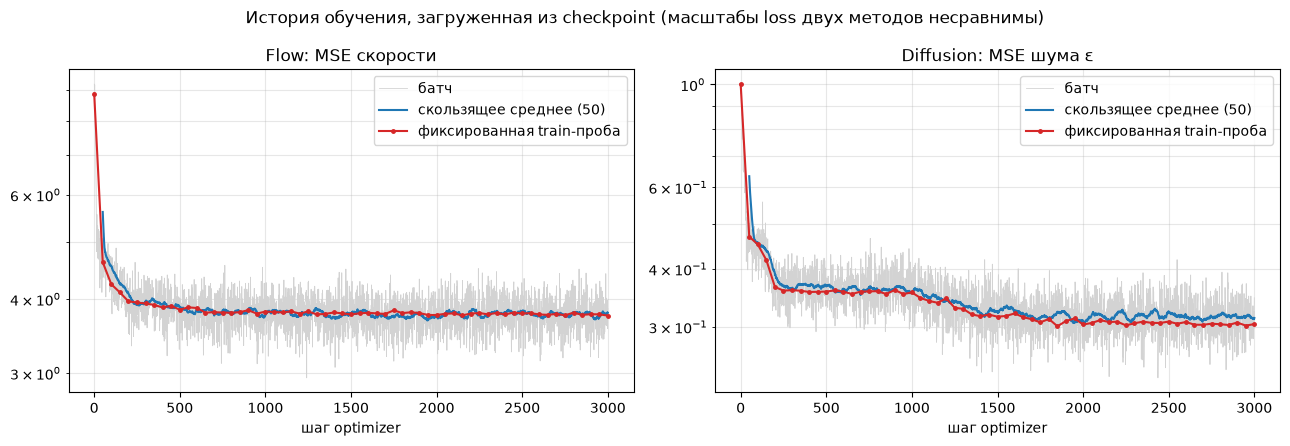

{'checkpoint': 'artifacts\\lab15\\checkpoints\\train_last.pt', 'checkpoint_step': 3000, 'n_steps': 3000, 'flow_weights_equal': True, 'diffusion_weights_equal': True, 'flow_outputs_equal': True, 'diffusion_outputs_equal': True, 'flow_adam_steps': [3000], 'diffusion_adam_steps': [3000], 'history_equal_to_memory': True, 'steps_consecutive_no_duplicates': True, 'equal_update_count': True}
flow      | probe: start 8.8891 -> end 3.7514 (min 3.7514) | batch last-100 mean 3.7571 | время 9.0 c
diffusion | probe: start 1.0016 -> end 0.3042 (min 0.3010) | batch last-100 mean 0.3143 | время 9.6 c


In [6]:
# Задание 5. История обучения, восстановленная из checkpoint: загружаем его в новые объекты моделей и
# оптимизаторов и проверяем, что веса, состояние Adam и история совпадают с только что обученными.
ckpt = torch.load(TRAIN_CKPT, map_location=DEVICE, weights_only=False)
restored_flow, restored_diffusion = make_mlp(), make_mlp()
restored_flow.load_state_dict(ckpt['flow_model']); restored_diffusion.load_state_dict(ckpt['diffusion_model'])
restored_flow_opt = torch.optim.Adam(restored_flow.parameters(), lr=LR)
restored_diffusion_opt = torch.optim.Adam(restored_diffusion.parameters(), lr=LR)
restored_flow_opt.load_state_dict(ckpt['flow_optimizer'])
restored_diffusion_opt.load_state_dict(ckpt['diffusion_optimizer'])
restored_flow.eval(); restored_diffusion.eval()
H = ckpt['history']

def adam_steps(optimizer):
    return sorted({int(s['step']) for s in optimizer.state_dict()['state'].values()})

with torch.no_grad():
    same_flow_out = torch.equal(restored_flow(probe_x1, probe_u), flow_model(probe_x1, probe_u))
    same_diff_out = torch.equal(restored_diffusion(probe_x1, probe_u), diffusion_model(probe_x1, probe_u))
resume_checks = {
    'checkpoint': str(TRAIN_CKPT), 'checkpoint_step': int(ckpt['step']), 'n_steps': N_STEPS,
    'flow_weights_equal': all(torch.equal(a, b) for a, b in zip(restored_flow.state_dict().values(),
                                                                flow_model.state_dict().values())),
    'diffusion_weights_equal': all(torch.equal(a, b) for a, b in zip(restored_diffusion.state_dict().values(),
                                                                     diffusion_model.state_dict().values())),
    'flow_outputs_equal': same_flow_out, 'diffusion_outputs_equal': same_diff_out,
    'flow_adam_steps': adam_steps(restored_flow_opt), 'diffusion_adam_steps': adam_steps(restored_diffusion_opt),
    'history_equal_to_memory': H == history,
    'steps_consecutive_no_duplicates': H['step'] == list(range(1, N_STEPS + 1)),
    'equal_update_count': len(H['flow_loss']) == len(H['diffusion_loss']) == N_STEPS,
}
assert resume_checks['flow_weights_equal'] and resume_checks['diffusion_weights_equal']
assert resume_checks['history_equal_to_memory'] and resume_checks['steps_consecutive_no_duplicates']
assert resume_checks['flow_adam_steps'] == resume_checks['diffusion_adam_steps'] == [N_STEPS]

# История из checkpoint (не из памяти) — в отдельные файлы для отчёта и следующих этапов.
save_json('train_history.json', {'source': str(TRAIN_CKPT), 'train_time': ckpt['train_time'], **H})
with open(ARTIFACTS / 'train_probe_log.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['step', 'flow_probe_loss', 'diffusion_probe_loss'])
    writer.writerows(zip(H['probe_step'], H['flow_probe'], H['diffusion_probe']))
save_json('resume_check.json', resume_checks)

def moving_average(values, k=50):
    values = np.asarray(values, dtype=float)
    k = max(1, min(k, len(values)))
    return np.convolve(values, np.ones(k) / k, mode='valid')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key, probe_key, title in [(axes[0], 'flow_loss', 'flow_probe', 'Flow: MSE скорости'),
                                  (axes[1], 'diffusion_loss', 'diffusion_probe', 'Diffusion: MSE шума ε')]:
    ma = moving_average(H[key])
    ax.plot(H['step'], H[key], color='lightgray', lw=0.6, label='батч')
    ax.plot(H['step'][len(H['step']) - len(ma):], ma, color='tab:blue', label='скользящее среднее (50)')
    ax.plot(H['probe_step'], H[probe_key], 'o-', ms=2.5, color='tab:red', label='фиксированная train-проба')
    ax.set_yscale('log'); ax.set_xlabel('шаг optimizer'); ax.set_title(title)
    ax.grid(alpha=0.3, which='both'); ax.legend()
fig.suptitle('История обучения, загруженная из checkpoint (масштабы loss двух методов несравнимы)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'training_history.png', dpi=120); plt.show()

print(resume_checks)
for name in ('flow', 'diffusion'):
    probe = H[f'{name}_probe']
    print(f"{name:9s} | probe: start {probe[0]:.4f} -> end {probe[-1]:.4f} (min {min(probe):.4f}) "
          f"| batch last-100 mean {np.mean(H[f'{name}_loss'][-100:]):.4f} "
          f"| время {ckpt['train_time'][f'{name}_s']:.1f} c")

**Как читать график `training_history.png`** (слева flow, справа diffusion):

- **MSE (mean squared error, средняя квадратичная ошибка)** — среднее квадратов разницы между ответом сети и правильным ответом: `MSE = mean((предсказание − цель)²)` по всем точкам батча и обеим координатам. Например, предсказание `(1, 2)` при цели `(3, −1)` даёт `((1−3)² + (2+1)²) / 2 = 6.5`. Квадрат сильнее штрафует крупные промахи, поэтому минимум MSE достигается на среднем значении цели.
- **Ось X** — шаг optimizer (одно обновление весов на батче из 512 точек), от 0 до `N_STEPS`.
- **Ось Y** — loss (MSE) в логарифмической шкале: у flow — промах в скорости `x1 − x0`, у diffusion — промах в шуме `ε`. Ниже — лучше; до нуля loss не дойдёт из-за неустранимого усреднения направлений.
- **Серая линия (батч)** — loss на текущем случайном батче; сильно дрожит из-за случайности батча.
- **Синяя линия (скользящее среднее, 50)** — сглаженная серая, показывает общую тенденцию.
- **Красная линия (фиксированная train-проба)** — loss на одних и тех же 2048 train-точках с тем же шумом и `t` каждые 50 шагов; меняется только из-за весов — главный индикатор обучения.

Высоту левой и правой панели сравнивать нельзя: это разные величины. Методы сравниваются по сэмплам в заданиях 7–8.

### Задание 6. Интеграторы и начальное распределение

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум.

**Результат.** Проверяемое состояние «Интеграторы и начальное распределение» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте ODE Euler и обратный шаг VP без сингулярного endpoint; создайте общий шум» и его результат доступен следующему этапу.

**Задание 6. Интеграторы и начальное распределение**

- **Что делали**: написали генерацию: Euler для flow (t: 0 → 1) и обратный ancestral-шаг VP (t: 1 → 0.001, без сингулярной точки t = 0, с клипом x̂0); создали общий стартовый шум `Z_COMMON` из 5000 точек.
- **Зачем**: превратить обученные модели в генераторы точек; общий шум нужен, чтобы методы отличались только способом генерации.
- **Результат**: `data/lab15/common_noise.pt`, `samplers.json`. Шум: среднее (−0.013, −0.009), дисперсии 0.97 и 1.01; доля шума в конце VP 0.0105, клип x̂0 ±7.95. Проверки «1 шаг Euler = z + v(z, 0)» и «VP воспроизводим при том же seed» — True.

In [7]:
# Задание 6. Интеграторы: Euler для ODE flow (t: 0 → 1) и обратный (ancestral) шаг VP diffusion (t: 1 → T_EPS).
# Обе выборки стартуют из одного общего шума Z ~ N(0, I) — различие в сэмплах идёт только от метода.
N_SAMPLES = len(X_test)                    # столько же точек, сколько в test
STEP_GRID = [1, 2, 5] if FAST_DEV_RUN else [1, 2, 5, 10, 20, 50, 100]   # число вызовов сети (NFE)
NOISE_SEED, ANCESTRAL_SEED = SEED + 6, SEED + 7
X0_CLIP = float(1.5 * np.abs(X_train).max())   # клип оценки x̂0 — по train, как [-1, 1] в DDPM

common_gen = torch.Generator().manual_seed(NOISE_SEED)
Z_COMMON = torch.randn(N_SAMPLES, 2, generator=common_gen).to(DEVICE)
torch.save({'z': Z_COMMON.cpu(), 'seed': NOISE_SEED}, DATA_ROOT / 'common_noise.pt')

@torch.no_grad()
def sample_flow_euler(model, z, n_steps, return_traj=False):
    """x_{k+1} = x_k + Δt · v_θ(x_k, t_k), t_k = k/n; старт x_0 = z при t = 0, финиш при t = 1."""
    x, dt = z.clone(), 1.0 / n_steps
    traj = [x.clone()]
    for k in range(n_steps):
        x = x + dt * model(x, torch.full((len(x),), k * dt, device=x.device))
        if return_traj:
            traj.append(x.clone())
    return (x, torch.stack(traj)) if return_traj else x

@torch.no_grad()
def sample_vp_ancestral(model, z, n_steps, seed=ANCESTRAL_SEED, clip=True, return_traj=False):
    """Обратные шаги VP по сетке t: 1 → T_EPS (t = 0 не используется: там 1 − ᾱ = 0 и шаг сингулярен).
    На шаге t → s: x̂0 из предсказанного ε, затем x_s ~ q(x_s | x_t, x̂0); на последнем шаге — без шума."""
    gen = torch.Generator().manual_seed(seed)
    ts = torch.linspace(1.0, T_EPS, n_steps + 1)
    x = z.clone()
    traj = [x.clone()]
    for i in range(n_steps):
        t, s = ts[i], ts[i + 1]
        ab_t, ab_s = vp_alpha_bar(t), vp_alpha_bar(s)
        alpha = ab_t / ab_s                     # ᾱ_t / ᾱ_s — доля сигнала, сохраняемая на интервале [s, t]
        eps = model(x, torch.full((len(x),), float(t), device=x.device))
        x0_hat = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        if clip:
            x0_hat = x0_hat.clamp(-X0_CLIP, X0_CLIP)
        coef_x0 = ab_s.sqrt() * (1 - alpha) / (1 - ab_t)
        coef_xt = alpha.sqrt() * (1 - ab_s) / (1 - ab_t)
        x = coef_x0 * x0_hat + coef_xt * x
        if i < n_steps - 1:
            var = (1 - ab_s) / (1 - ab_t) * (1 - alpha)
            x = x + var.sqrt() * torch.randn(x.shape, generator=gen).to(x.device)
        if return_traj:
            traj.append(x.clone())
    return (x, torch.stack(traj)) if return_traj else x

# Начальное распределение: общий шум действительно ≈ N(0, I) и совпадает с тем, откуда стартуют оба метода.
z_np = Z_COMMON.cpu().numpy()
start_stats = {'n': N_SAMPLES, 'seed': NOISE_SEED, 'mean': z_np.mean(0).tolist(),
               'cov': np.cov(z_np.T).tolist(), 'mean_radius': float(np.linalg.norm(z_np, axis=1).mean())}
ab_end = float(vp_alpha_bar(torch.tensor(T_EPS)))
endpoint = {'vp_t_end': T_EPS, 'noise_coef_at_end': (1 - ab_end) ** 0.5,
            'vp_t_start': 1.0, 'signal_coef_at_start': float(vp_alpha_bar(torch.tensor(1.0)).sqrt()),
            'x0_clip': X0_CLIP}

# Проверки интеграторов на общем шуме: конечность, детерминизм, 1 шаг Euler = z + v(z, 0), траектории сохраняются.
sanity = {}
with torch.no_grad():
    one_step = sample_flow_euler(flow_model, Z_COMMON, 1)
    sanity['euler_1step_matches_formula'] = bool(torch.allclose(
        one_step, Z_COMMON + flow_model(Z_COMMON, torch.zeros(N_SAMPLES, device=DEVICE)), atol=1e-6))
    for n in (STEP_GRID[0], STEP_GRID[-1]):
        xf, tf = sample_flow_euler(flow_model, Z_COMMON, n, return_traj=True)
        xd, td = sample_vp_ancestral(diffusion_model, Z_COMMON, n, return_traj=True)
        sanity[f'steps_{n}'] = {
            'flow_finite': bool(torch.isfinite(xf).all()), 'vp_finite': bool(torch.isfinite(xd).all()),
            'flow_traj_shape': list(tf.shape), 'vp_traj_shape': list(td.shape),
            'flow_mean_radius': float(xf.norm(dim=1).mean()), 'vp_mean_radius': float(xd.norm(dim=1).mean()),
        }
    sanity['vp_deterministic_given_seed'] = bool(torch.equal(sample_vp_ancestral(diffusion_model, Z_COMMON, 5),
                                                             sample_vp_ancestral(diffusion_model, Z_COMMON, 5)))
assert sanity['euler_1step_matches_formula'] and sanity['vp_deterministic_given_seed']
assert all(v['flow_finite'] and v['vp_finite'] for k, v in sanity.items() if k.startswith('steps_'))

save_json('samplers.json', {
    'flow': 'Euler ODE, t = k/n, k = 0..n−1, старт t = 0 (шум)',
    'diffusion': 'VP ancestral (DDPM posterior), сетка linspace(1, T_EPS, n+1), последний шаг без шума, клип x̂0',
    'n_samples': N_SAMPLES, 'step_grid': STEP_GRID, 'common_noise': str(DATA_ROOT / 'common_noise.pt'),
    'ancestral_seed': ANCESTRAL_SEED, 'start_distribution': start_stats, 'endpoint': endpoint, 'sanity': sanity})

print({'n_samples': N_SAMPLES, 'step_grid': STEP_GRID, 'noise_mean': np.round(start_stats['mean'], 3).tolist(),
       'noise_cov': np.round(start_stats['cov'], 3).tolist()})
print(endpoint)
print(json.dumps(sanity, ensure_ascii=False))

{'n_samples': 5000, 'step_grid': [1, 2, 5, 10, 20, 50, 100], 'noise_mean': [-0.013, -0.009], 'noise_cov': [[0.968, 0.006], [0.006, 1.013]]}
{'vp_t_end': 0.001, 'noise_coef_at_end': 0.01048668534907936, 'vp_t_start': 1.0, 'signal_coef_at_start': 0.006571585778146982, 'x0_clip': 7.947113990783691}
{"euler_1step_matches_formula": true, "steps_1": {"flow_finite": true, "vp_finite": true, "flow_traj_shape": [2, 5000, 2], "vp_traj_shape": [2, 5000, 2], "flow_mean_radius": 0.39755305647850037, "vp_mean_radius": 7.024537086486816}, "steps_100": {"flow_finite": true, "vp_finite": true, "flow_traj_shape": [101, 5000, 2], "vp_traj_shape": [101, 5000, 2], "flow_mean_radius": 3.9500937461853027, "vp_mean_radius": 4.065810680389404}, "vp_deterministic_given_seed": true}


Подготовили функции

### Задание 7. Оценка покрытия мод на test

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте качество каждого sampler по независимому test и сохраните изображения.

**Результат.** Проверяемое состояние «Оценка покрытия мод на test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте качество каждого sampler по независимому test и сохраните изображения» и его результат доступен следующему этапу.

Сэмплер выдает новые точки. На вход мы подаем сгенерированные шумы и случайные точки в центре. Каждый раз мы спрашиваем две нейроынные сети о шуме и о векторе. Точки сдвигаются и в итоге разводятся по модам. Разведенные точки сравниваются с тестовыми.

**Задание 7. Оценка покрытия мод на test**

- **Что делали**: сгенерировали по 5000 точек из `Z_COMMON` для flow и VP ancestral при 1, 2, 5, 10, 20, 50, 100 шагах и сравнили с test: покрытие мод, доля в модах, TV, SW1, MMD, радиус, разброс в моде, время.
- **Зачем**: качество измеряется по сэмплам относительно независимого test, а не по train loss.
- **Результат**: `sample_quality.json`, `samples.npz`, `figures/samples_grid.png`, `figures/quality_vs_steps.png`. Эталон train vs test: 0.990 в модах, SW1 0.049. В модах при 1 / 5 / 100 шагах: flow 0.000 / 0.796 / 0.930, VP 0.046 / 0.789 / 0.965; SW1 при 100 шагах: flow 0.125, VP 0.121.

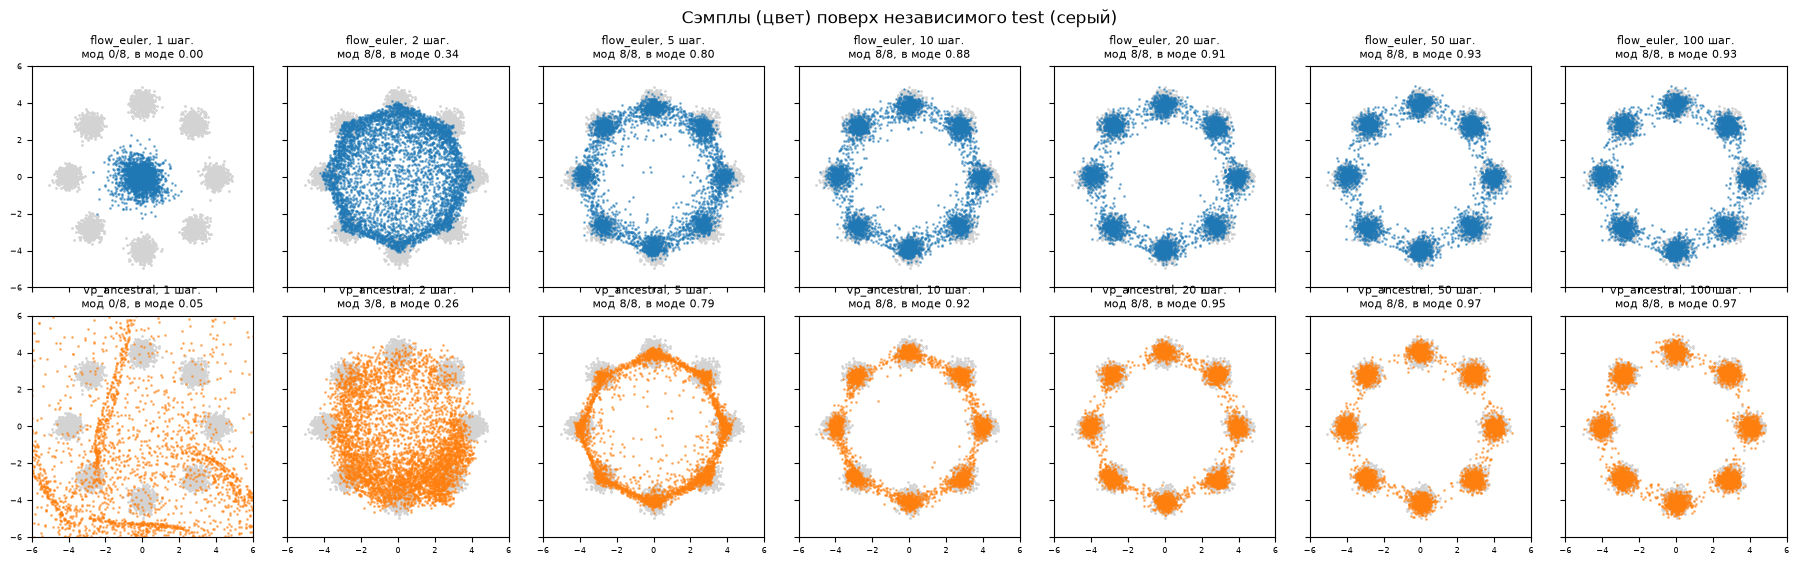

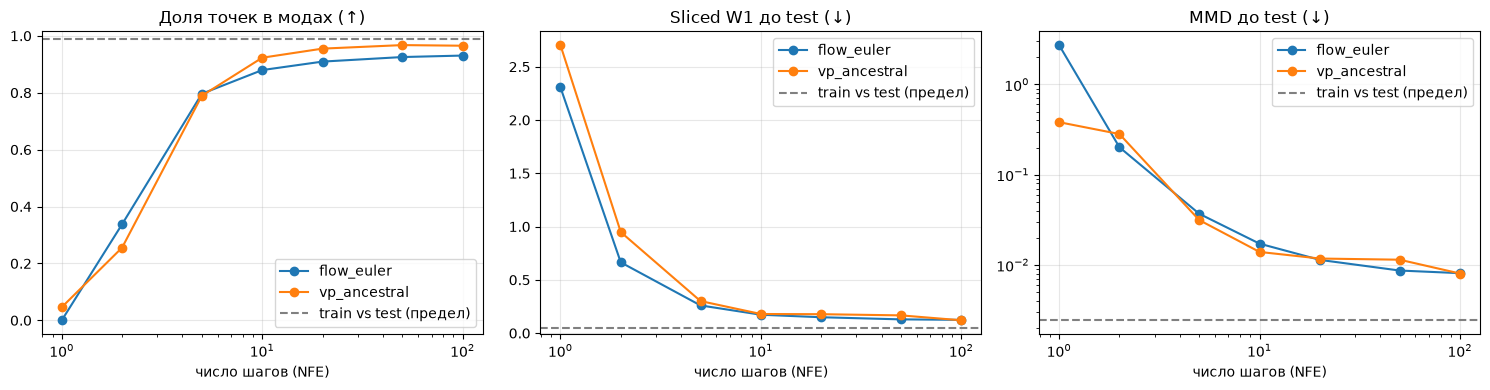

sampler,шагов,мод покрыто,в модах,TV мод,SW1,MMD,радиус,std в моде,NaN/inf,"время, с"
train_reference,0,8,0.990,0.014,0.0494,0.00244,4.009,0.294,0,0.000
flow_euler,1,0,0.000,0.990,2.3070,2.72845,0.398,—,0,0.001
flow_euler,2,8,0.338,0.653,0.6641,0.20140,3.042,0.300,0,0.003
flow_euler,5,8,0.796,0.194,0.2600,0.03690,3.707,0.276,0,0.004
flow_euler,10,8,0.880,0.119,0.1726,0.01721,3.830,0.290,0,0.007
flow_euler,20,8,0.909,0.096,0.1492,0.01137,3.893,0.295,0,0.016
flow_euler,50,8,0.925,0.081,0.1291,0.00867,3.936,0.296,0,0.043
flow_euler,100,8,0.931,0.077,0.1247,0.00811,3.950,0.296,0,0.076
vp_ancestral,1,0,0.046,0.944,2.7030,0.38169,7.025,0.431,0,0.002
vp_ancestral,2,3,0.256,0.735,0.9483,0.28205,3.079,0.363,0,0.003


In [8]:
# Задание 7. Качество каждого sampler (flow Euler / VP ancestral × число шагов) по независимому test.
# Все сэмплы — из общего шума Z_COMMON; test используется только для измерения, не для выбора настроек.
IN_MODE_RADIUS = 3 * MODE_STD        # точка «попала в моду», если ближе 3σ к центру
COVER_MIN_FRAC = 0.25                # мода покрыта, если в ней ≥ 25% от ожидаемой доли N/8 сэмплов
N_PROJ = 128                         # проекций для sliced Wasserstein
MMD_N = min(2000, len(X_test))       # подвыборка для MMD (матрица ядра ≤ 2000 × 2000; в FAST test меньше)
MMD_BANDWIDTHS = [0.25, 0.5, 1.0, 2.0]

proj_gen = torch.Generator().manual_seed(SEED + 8)
PROJ = torch.randn(N_PROJ, 2, generator=proj_gen)
PROJ = (PROJ / PROJ.norm(dim=1, keepdim=True)).numpy()
def mode_histogram(modes, in_mode):
    """Доли точек по 8 модам + девятая корзина «вне мод» (иначе облако в центре выглядело бы сбалансированным)."""
    hist = np.bincount(np.where(in_mode, modes, N_MODES), minlength=N_MODES + 1)
    return hist / len(modes)

test_modes, test_dist = assign_modes(X_test)
test_mode_frac = mode_histogram(test_modes, test_dist < IN_MODE_RADIUS)
mmd_idx = np.random.default_rng(SEED + 9).choice(len(X_test), MMD_N, replace=False)

def sliced_wasserstein(a, b):
    """Среднее по случайным направлениям W1 между одномерными проекциями (n сэмплов = n test)."""
    pa, pb = np.sort(a @ PROJ.T, axis=0), np.sort(b @ PROJ.T, axis=0)
    return float(np.abs(pa - pb).mean())

def mmd_rbf(a, b):
    a, b = torch.from_numpy(a[:MMD_N]).double(), torch.from_numpy(b).double()
    d_aa, d_bb, d_ab = torch.cdist(a, a) ** 2, torch.cdist(b, b) ** 2, torch.cdist(a, b) ** 2
    k = lambda d: sum(torch.exp(-d / (2 * h ** 2)) for h in MMD_BANDWIDTHS)
    return float(k(d_aa).mean() + k(d_bb).mean() - 2 * k(d_ab).mean())

def sample_quality(points):
    points = np.asarray(points, dtype=np.float32)
    finite = np.isfinite(points).all(1)
    pts = np.where(finite[:, None], points, 1e6)          # нечисловые точки считаются промахом
    modes, dist = assign_modes(pts)
    in_mode = dist < IN_MODE_RADIUS
    counts = np.bincount(modes[in_mode], minlength=N_MODES)
    mode_frac = mode_histogram(modes, in_mode)
    covered = int((counts >= COVER_MIN_FRAC * len(pts) / N_MODES).sum())
    per_mode_std = [float(pts[in_mode & (modes == k)].std(axis=0).mean()) if counts[k] > 1 else float('nan')
                    for k in range(N_MODES)]   # std по каждой оси, затем среднее по осям
    return {
        'modes_covered': covered,                                   # из 8
        'in_mode_frac': float(in_mode.mean()),                      # доля «качественных» точек
        'mode_tv_vs_test': float(0.5 * np.abs(mode_frac - test_mode_frac).sum()),   # 0 — доли мод как в test, 1 — всё мимо
        'sliced_w1_vs_test': sliced_wasserstein(pts, X_test),
        'mmd_vs_test': mmd_rbf(pts, X_test[mmd_idx]),
        'mean_radius': float(np.linalg.norm(pts, axis=1).mean()),
        'in_mode_std_mean': float(np.nanmean(per_mode_std)) if counts.sum() > 1 else float('nan'),  # ≈ MODE_STD
        'non_finite': int((~finite).sum()),
        'mode_counts': counts.tolist(),
    }

# Опорный уровень: независимая train-выборка того же размера против test — лучше этого sampler быть не может.
ref_idx = np.random.default_rng(SEED + 10).choice(len(X_train), N_SAMPLES, replace=False)
reference = {'method': 'train_reference', 'n_steps': 0, 'sampling_time_s': 0.0, **sample_quality(X_train[ref_idx])}

SAMPLERS = {'flow_euler': lambda n: sample_flow_euler(flow_model, Z_COMMON, n),
            'vp_ancestral': lambda n: sample_vp_ancestral(diffusion_model, Z_COMMON, n)}
SAMPLES, SAMPLE_ROWS = {}, [reference]
for method, sampler in SAMPLERS.items():
    for n in STEP_GRID:
        sync(); t0 = time.perf_counter()
        x = sampler(n)
        sync(); elapsed = time.perf_counter() - t0
        SAMPLES[(method, n)] = x.cpu().numpy()
        SAMPLE_ROWS.append({'method': method, 'n_steps': n, 'nfe': n, 'sampling_time_s': elapsed,
                            **sample_quality(SAMPLES[(method, n)])})

np.savez_compressed(ARTIFACTS / 'samples.npz', **{f'{m}_{n}': v for (m, n), v in SAMPLES.items()})
save_json('sample_quality.json', {'in_mode_radius': IN_MODE_RADIUS, 'cover_min_frac': COVER_MIN_FRAC,
                                  'n_proj': N_PROJ, 'mmd_n': MMD_N, 'mmd_bandwidths': MMD_BANDWIDTHS,
                                  'n_samples': N_SAMPLES, 'test_n': int(len(X_test)), 'rows': SAMPLE_ROWS})

# Изображения: сэмплы поверх test для каждого sampler и числа шагов.
fig, axes = plt.subplots(len(SAMPLERS), len(STEP_GRID), figsize=(2.6 * len(STEP_GRID), 2.8 * len(SAMPLERS)),
                         sharex=True, sharey=True, squeeze=False)
rows_by_key = {(r['method'], r['n_steps']): r for r in SAMPLE_ROWS}
for i, method in enumerate(SAMPLERS):
    for j, n in enumerate(STEP_GRID):
        ax, pts, r = axes[i, j], SAMPLES[(method, n)], rows_by_key[(method, n)]
        ax.scatter(X_test[:, 0], X_test[:, 1], s=1, c='lightgray')
        ax.scatter(pts[:, 0], pts[:, 1], s=1, c='tab:blue' if method == 'flow_euler' else 'tab:orange', alpha=0.5)
        ax.set_title(f"{method}, {n} шаг.\nмод {r['modes_covered']}/8, в моде {r['in_mode_frac']:.2f}", fontsize=8)
        ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect('equal'); ax.tick_params(labelsize=6)
fig.suptitle('Сэмплы (цвет) поверх независимого test (серый)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'samples_grid.png', dpi=120); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for method, color in [('flow_euler', 'tab:blue'), ('vp_ancestral', 'tab:orange')]:
    rs = [rows_by_key[(method, n)] for n in STEP_GRID]
    axes[0].plot(STEP_GRID, [r['in_mode_frac'] for r in rs], 'o-', color=color, label=method)
    axes[1].plot(STEP_GRID, [r['sliced_w1_vs_test'] for r in rs], 'o-', color=color, label=method)
    axes[2].plot(STEP_GRID, [max(r['mmd_vs_test'], 1e-6) for r in rs], 'o-', color=color, label=method)
for ax, key, title in [(axes[0], 'in_mode_frac', 'Доля точек в модах (↑)'),
                       (axes[1], 'sliced_w1_vs_test', 'Sliced W1 до test (↓)'),
                       (axes[2], 'mmd_vs_test', 'MMD до test (↓)')]:
    ax.axhline(max(reference[key], 1e-6), color='gray', ls='--', label='train vs test (предел)')
    ax.set_xscale('log'); ax.set_xlabel('число шагов (NFE)'); ax.set_title(title); ax.grid(alpha=0.3); ax.legend()
axes[2].set_yscale('log')
fig.tight_layout(); fig.savefig(FIG_DIR / 'quality_vs_steps.png', dpi=120); plt.show()

# Таблица — HTML со стилями CSS (как в lab14): границы, полосы строк, лучший sampler по каждой метрике выделен.
import pandas as pd
from IPython.display import display

TABLE_CSS = [
    {'selector': '', 'props': 'border-collapse: collapse; font-size: 12px; margin: 4px 0 14px 0;'},
    {'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold; padding: 4px 0;'},
    {'selector': 'th, td', 'props': 'border: 1px solid rgba(127,127,127,0.55); padding: 3px 8px; text-align: right;'},
    {'selector': 'th', 'props': 'background: rgba(127,127,127,0.22); white-space: normal; text-align: center;'},
    {'selector': 'tbody tr:nth-child(even)', 'props': 'background: rgba(127,127,127,0.09);'},
    {'selector': 'tbody tr:hover', 'props': 'background: rgba(66,133,244,0.18);'},
]
BEST_PROPS = 'font-weight: bold; text-decoration: underline;'

def show_table(df, caption, formats, best_max=(), best_min=(), ref_rows=()):
    """best_max / best_min — столбцы, где выделить лучшее значение среди строк, не входящих в ref_rows."""
    rows = [i for i in df.index if i not in ref_rows]
    sty = (df.style.hide(axis='index').set_caption(caption).set_table_styles(TABLE_CSS).format(formats, na_rep='—'))
    if best_max:
        sty = sty.highlight_max(subset=(rows, list(best_max)), props=BEST_PROPS)
    if best_min:
        sty = sty.highlight_min(subset=(rows, list(best_min)), props=BEST_PROPS)
    if ref_rows:
        sty = sty.apply(lambda r: ['font-style: italic; color: gray;' if r.name in ref_rows else '' for _ in r], axis=1)
    display(sty)

quality_view = pd.DataFrame(SAMPLE_ROWS).drop(columns=['mode_counts', 'nfe']).rename(columns={
    'method': 'sampler', 'n_steps': 'шагов', 'modes_covered': 'мод покрыто', 'in_mode_frac': 'в модах',
    'mode_tv_vs_test': 'TV мод', 'sliced_w1_vs_test': 'SW1', 'mmd_vs_test': 'MMD', 'mean_radius': 'радиус',
    'in_mode_std_mean': 'std в моде', 'non_finite': 'NaN/inf', 'sampling_time_s': 'время, с'})
quality_view = quality_view[['sampler', 'шагов', 'мод покрыто', 'в модах', 'TV мод', 'SW1', 'MMD',
                             'радиус', 'std в моде', 'NaN/inf', 'время, с']]
show_table(quality_view, f'Качество сэмплов относительно test (n = {N_SAMPLES}; эталон — train vs test)',
           formats={'в модах': '{:.3f}', 'TV мод': '{:.3f}', 'SW1': '{:.4f}', 'MMD': '{:.5f}',
                    'радиус': '{:.3f}', 'std в моде': '{:.3f}', 'время, с': '{:.3f}'},
           best_max=('мод покрыто', 'в модах'), best_min=('TV мод', 'SW1', 'MMD'), ref_rows=(0,))

**Как читать таблицу качества сэмплов.** Каждая строка — один sampler с заданным числом шагов; 5000 точек из общего шума сравниваются с независимым test. Первая строка (серым курсивом) — эталон: настоящие train-точки против test, лучше этого генератор быть не может. Подчёркнуто лучшее значение среди sampler'ов.

| Столбец | Что означает | Лучше |
|---|---|---|
| **sampler** | метод генерации: `flow_euler` — шаги Эйлера по полю скорости, `vp_ancestral` — обратные шаги VP diffusion | — |
| **шагов** | сколько раз вызывается сеть при генерации (NFE); больше — точнее, но дольше | меньше при том же качестве |
| **мод покрыто** | сколько из 8 мод получили хотя бы четверть ожидаемой доли точек (N/8) | 8 |
| **в модах** | доля точек ближе 3σ = 0.9 к центру какой-либо моды — «качественные» точки | 1 (эталон ≈ 0.99) |
| **TV мод** | расхождение долей точек по 8 модам и корзине «вне мод» с такими же долями в test: 0 — пропорции как в test, 1 — всё мимо | 0 |
| **SW1** | sliced Wasserstein: средняя по 128 случайным направлениям «работа» по перемещению облака сэмплов в облако test | 0 |
| **MMD** | maximum mean discrepancy с гауссовыми ядрами: различие двух облаков точек на нескольких масштабах | 0 |
| **радиус** | средний радиус точек; у данных ≈ 4, у шума ≈ 1.25 | ≈ 4 |
| **std в моде** | средний разброс точек внутри мод; у данных 0.3. Меньше — моды «сжаты», больше — размыты | ≈ 0.3 |
| **NaN/inf** | число нечисловых точек (сломанная генерация) | 0 |
| **время, с** | время генерации всех 5000 точек | меньше |

**в модах** и **мод покрыто** проверяют точность и покрытие; **SW1** и **MMD** сравнивают распределения целиком, включая форму и пропорции мод.

### Задание 8. Сводная таблица выборок

*Вес: 1 балл.*

**Постановка.** Качество распределения должно измеряться по сэмплам относительно независимого test, а не по обучающему loss. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses.

**Результат.** Проверяемое состояние «Сводная таблица выборок» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните эмпирические метрики выборок и время, не сравнивая напрямую train losses» и его результат доступен следующему этапу.

Делаем повторы на разном шуме, чтобы не зависить от случайности эксперимента

**Задание 8. Сводная таблица выборок**

- **Что делали**: повторили генерацию ещё на двух независимых наборах шума и свели метрики в таблицу «среднее ± std» со временем генерации и обучения; нашли минимальное число шагов до цели (≥ 0.95 в модах, 8/8 мод).
- **Зачем**: отделить разницу методов от случайности стартового шума и сравнить цену качества по времени, не сравнивая train losses.
- **Результат**: `sample_summary.csv`, `sample_summary.json`, `sample_metrics_repeats.csv`. Цели достиг только VP ancestral — с 20 шагов (SW1 0.173, 0.036 с); flow вышел на плато 0.932 в модах. Лучший SW1: VP 0.121, flow 0.142 (оба при 100 шагах); std по повторам ≤ 0.02.

In [9]:
# Задание 8. Сводная таблица выборок: эмпирические метрики сэмплов против test и время.
# Train losses сюда не входят: MSE скорости (flow) и MSE шума (diffusion) — разные величины и не сравнимы.
# Чтобы отделить эффект метода от случайности стартового шума, каждый sampler повторяется на ещё двух
# независимых наборах шума (кроме Z_COMMON) — в таблице среднее ± std по трём повторам.
EXTRA_NOISE_SEEDS = [SEED + 100, SEED + 200]
QUALITY_TARGET = {'in_mode_frac': 0.95, 'modes_covered': N_MODES}   # «достаточно хорошо» для минимального NFE

def run_sampler(method, z, n):
    sync(); t0 = time.perf_counter()
    x = sample_flow_euler(flow_model, z, n) if method == 'flow_euler' else sample_vp_ancestral(diffusion_model, z, n)
    sync()
    return x.cpu().numpy(), time.perf_counter() - t0

repeat_rows = [dict(r, noise='Z_COMMON') for r in SAMPLE_ROWS if r['method'] != 'train_reference']
for seed in EXTRA_NOISE_SEEDS:
    z = torch.randn(N_SAMPLES, 2, generator=torch.Generator().manual_seed(seed)).to(DEVICE)
    for method in SAMPLERS:
        for n in STEP_GRID:
            pts, elapsed = run_sampler(method, z, n)
            repeat_rows.append({'method': method, 'n_steps': n, 'nfe': n, 'sampling_time_s': elapsed,
                                'noise': f'seed_{seed}', **sample_quality(pts)})
repeats = pd.DataFrame(repeat_rows)
repeats.drop(columns=['mode_counts']).to_csv(ARTIFACTS / 'sample_metrics_repeats.csv', index=False)

METRICS = ['modes_covered', 'in_mode_frac', 'mode_tv_vs_test', 'sliced_w1_vs_test', 'mmd_vs_test',
           'mean_radius', 'in_mode_std_mean', 'sampling_time_s']
agg = repeats.groupby(['method', 'n_steps'])[METRICS].agg(['mean', 'std'])
agg.columns = [f'{m}_{s}' for m, s in agg.columns]
summary = agg.reset_index()
summary['time_per_nfe_ms'] = 1000 * summary['sampling_time_s_mean'] / summary['n_steps']
summary['train_time_s'] = summary['method'].map({'flow_euler': train_time['flow_s'],
                                                 'vp_ancestral': train_time['diffusion_s']})
summary['n_repeats'] = repeats.groupby(['method', 'n_steps']).size().values
summary.to_csv(ARTIFACTS / 'sample_summary.csv', index=False)

# Минимальное число шагов, при котором в среднем по повторам достигнут целевой уровень качества.
def min_steps_to_target(method):
    rows = summary[(summary['method'] == method) & (summary['in_mode_frac_mean'] >= QUALITY_TARGET['in_mode_frac'])
                   & (summary['modes_covered_mean'] >= QUALITY_TARGET['modes_covered'])]
    return None if rows.empty else rows.sort_values('n_steps').iloc[0]

verdict = []
for method in SAMPLERS:
    best = summary[summary['method'] == method].sort_values('sliced_w1_vs_test_mean').iloc[0]
    first = min_steps_to_target(method)
    verdict.append({'sampler': method,
                    'мин. шагов до цели': float('nan') if first is None else int(first['n_steps']),
                    'SW1 при мин. шагах': float('nan') if first is None else float(first['sliced_w1_vs_test_mean']),
                    'время при мин. шагах, с': float('nan') if first is None else float(first['sampling_time_s_mean']),
                    'лучший SW1': float(best['sliced_w1_vs_test_mean']), 'шагов у лучшего SW1': int(best['n_steps']),
                    'обучение, с': float(best['train_time_s'])})
verdict = pd.DataFrame(verdict)

save_json('sample_summary.json', {
    'n_samples': N_SAMPLES, 'noise_sets': ['Z_COMMON'] + [f'seed_{s}' for s in EXTRA_NOISE_SEEDS],
    'quality_target': QUALITY_TARGET, 'reference_train_vs_test': {k: reference[k] for k in METRICS if k in reference},
    'rows': summary.to_dict(orient='records'), 'verdict': verdict.to_dict(orient='records'),
    'note': 'train losses не сравниваются: MSE скорости и MSE шума — разные величины'})

def pm(mean, std, fmt):
    return f'{mean:{fmt}} ± {std:{fmt}}'

view = pd.DataFrame({
    'sampler': summary['method'], 'шагов': summary['n_steps'],
    'мод покрыто': summary['modes_covered_mean'],
    'в модах': [pm(m, s, '.3f') for m, s in zip(summary['in_mode_frac_mean'], summary['in_mode_frac_std'])],
    'TV мод': summary['mode_tv_vs_test_mean'],
    'SW1': [pm(m, s, '.4f') for m, s in zip(summary['sliced_w1_vs_test_mean'], summary['sliced_w1_vs_test_std'])],
    'MMD': summary['mmd_vs_test_mean'], 'радиус': summary['mean_radius_mean'],
    'std в моде': summary['in_mode_std_mean_mean'],
    'время, с': summary['sampling_time_s_mean'], 'мс / шаг': summary['time_per_nfe_ms'],
    'обучение, с': summary['train_time_s']})
ref_row = pd.DataFrame([{'sampler': 'train_reference', 'шагов': 0, 'мод покрыто': reference['modes_covered'],
                         'в модах': f"{reference['in_mode_frac']:.3f}", 'TV мод': reference['mode_tv_vs_test'],
                         'SW1': f"{reference['sliced_w1_vs_test']:.4f}", 'MMD': reference['mmd_vs_test'],
                         'радиус': reference['mean_radius'], 'std в моде': reference['in_mode_std_mean'],
                         'время, с': 0.0, 'мс / шаг': float('nan'), 'обучение, с': float('nan')}])
view = pd.concat([ref_row, view], ignore_index=True)
show_table(view, f'Сводная таблица выборок: среднее (± std) по {len(EXTRA_NOISE_SEEDS) + 1} наборам шума, n = {N_SAMPLES}',
           formats={'мод покрыто': '{:.1f}', 'TV мод': '{:.3f}', 'MMD': '{:.5f}', 'радиус': '{:.3f}',
                    'std в моде': '{:.3f}', 'время, с': '{:.3f}', 'мс / шаг': '{:.2f}', 'обучение, с': '{:.1f}'},
           best_max=('мод покрыто',), best_min=('TV мод', 'MMD'), ref_rows=(0,))
show_table(verdict, f"Итог по sampler'ам (цель: в модах ≥ {QUALITY_TARGET['in_mode_frac']}, покрыто {N_MODES}/8 мод)",
           formats={'мин. шагов до цели': '{:.0f}', 'SW1 при мин. шагах': '{:.4f}', 'время при мин. шагах, с': '{:.3f}',
                    'лучший SW1': '{:.4f}', 'обучение, с': '{:.1f}'},
           best_min=('мин. шагов до цели', 'лучший SW1'))
print('сохранено:', ARTIFACTS / 'sample_summary.csv', ARTIFACTS / 'sample_summary.json',
      ARTIFACTS / 'sample_metrics_repeats.csv')

sampler,шагов,мод покрыто,в модах,TV мод,SW1,MMD,радиус,std в моде,"время, с",мс / шаг,"обучение, с"
train_reference,0,8.0,0.990,0.014,0.0494,0.00244,4.009,0.294,0.000,—,—
flow_euler,1,0.0,0.000 ± 0.000,0.990,2.3106 ± 0.0034,2.75242,0.392,—,0.007,6.67,9.0
flow_euler,2,8.0,0.344 ± 0.005,0.647,0.6726 ± 0.0091,0.20231,3.037,0.300,0.013,6.67,9.0
flow_euler,5,8.0,0.802 ± 0.007,0.189,0.2752 ± 0.0159,0.03878,3.704,0.276,0.025,4.98,9.0
flow_euler,10,8.0,0.881 ± 0.001,0.117,0.1875 ± 0.0186,0.01870,3.827,0.288,0.045,4.48,9.0
flow_euler,20,8.0,0.910 ± 0.001,0.095,0.1661 ± 0.0196,0.01263,3.890,0.293,0.055,2.77,9.0
flow_euler,50,8.0,0.927 ± 0.003,0.081,0.1462 ± 0.0207,0.00989,3.934,0.294,0.057,1.13,9.0
flow_euler,100,8.0,0.932 ± 0.002,0.078,0.1417 ± 0.0206,0.00932,3.948,0.294,0.112,1.12,9.0
vp_ancestral,1,0.0,0.045 ± 0.002,0.945,2.6812 ± 0.0365,0.37957,7.009,0.426,0.002,1.89,9.6
vp_ancestral,2,3.7,0.262 ± 0.005,0.729,0.9423 ± 0.0181,0.27907,3.082,0.370,0.004,1.82,9.6


sampler,мин. шагов до цели,SW1 при мин. шагах,"время при мин. шагах, с",лучший SW1,шагов у лучшего SW1,"обучение, с"
flow_euler,—,—,—,0.1417,100,9.0
vp_ancestral,20,0.1732,0.036,0.1212,100,9.6


сохранено: artifacts\lab15\sample_summary.csv artifacts\lab15\sample_summary.json artifacts\lab15\sample_metrics_repeats.csv


### Задание 9. Альтернативное coupling

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите поле с угловым pairing на тех же данных и бюджете.

**Результат.** Проверяемое состояние «Альтернативное coupling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите поле с угловым pairing на тех же данных и бюджете» и его результат доступен следующему этапу.

**Задание 9. Альтернативное coupling**

- **Что делали**: обучили третью сеть — flow с угловым pairing: внутри батча шум и точки данных сортируются по углу и соединяются по порядку. Те же инициализация, батчи, шум, t и 3000 шагов, что у flow.
- **Зачем**: проверить, что «разумные» пары выпрямляют поле и сокращают число шагов генерации.
- **Результат**: `angular_coupling.json`, `samples_angular.npz`, `figures/angular_pairing.png`, `checkpoints/angular_last.pt`. Пар в своём секторе 100% против 12%, длина пути 2.81 против 4.15; обучение 9.9 с. За 1 шаг: 0.762 в модах и SW1 0.144 (обычный flow: 0.000 и 2.31); за 100 шагов: 0.916 и SW1 0.073 — лучший SW1 из всех.

C:\Users\bogom\AppData\Local\Temp\ipykernel_35240\1407550345.py:61: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  angular_history['step'].append(step); angular_history['loss'].append(float(loss))


step   500 | angular flow batch 0.2444 probe 0.3483
step  1000 | angular flow batch 0.2651 probe 0.2698
step  1500 | angular flow batch 0.2996 probe 0.1831
step  2000 | angular flow batch 0.2264 probe 0.2010
step  2500 | angular flow batch 0.2460 probe 0.2234
step  3000 | angular flow batch 0.3591 probe 0.2295


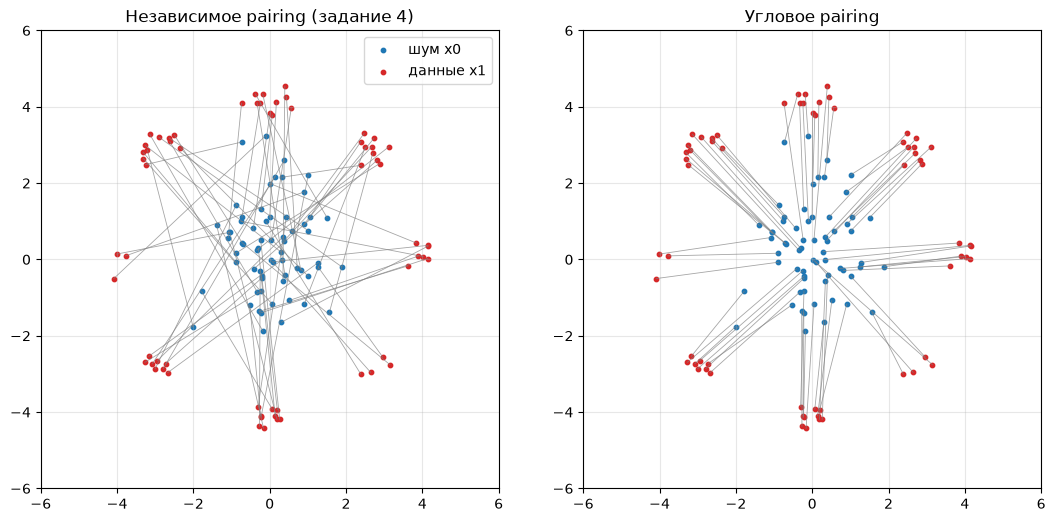

pairing,средняя длина пути,средний |x1 − x0|²,в том же секторе,"средняя разница углов, °"
independent,4.149,18.243,0.121,91.2
angular,2.809,8.375,1.000,8.0


sampler,шагов,мод покрыто,в модах,TV мод,SW1,MMD,радиус,std в моде,"время, с"
flow_angular,1,8,0.762,0.229,0.1443,0.03250,3.893,0.270,0.001
flow_euler,1,0,0.000,0.990,2.3070,2.72845,0.398,—,0.001
flow_angular,2,8,0.828,0.162,0.1103,0.01847,3.917,0.268,0.002
flow_euler,2,8,0.338,0.653,0.6641,0.20140,3.042,0.300,0.003
flow_angular,5,8,0.887,0.103,0.0851,0.00937,3.952,0.277,0.007
flow_euler,5,8,0.796,0.194,0.2600,0.03690,3.707,0.276,0.004
flow_angular,10,8,0.905,0.085,0.0749,0.00752,3.965,0.282,0.011
flow_euler,10,8,0.880,0.119,0.1726,0.01721,3.830,0.290,0.007
flow_angular,20,8,0.910,0.081,0.0719,0.00692,3.971,0.282,0.022
flow_euler,20,8,0.909,0.096,0.1492,0.01137,3.893,0.295,0.016


{'angular_train_time_s': 9.9, 'flow_train_time_s': 9.0, 'angular_probe': (4.1887, 0.2295)}


In [10]:
# Задание 9. Альтернативное coupling: угловое pairing внутри батча.
# Батч точек данных, батч шума и t — ровно те же, что при обучении flow в задании 4 (тот же генератор и порядок),
# меняется только то, какой шум с какой точкой образует пару: шум и данные сортируются по углу и
# сопоставляются по рангу. Маргиналы не меняются (это перестановка внутри батча), меняется target field x1 − x0.
ANGULAR_CKPT = CKPT_DIR / ('angular_last_fast.pt' if FAST_DEV_RUN else 'angular_last.pt')

def angular_pairing(noise, x1):
    """Переставляет x1 так, чтобы i-й по углу шум получил i-ю по углу точку данных."""
    order_noise = torch.argsort(torch.atan2(noise[:, 1], noise[:, 0]))
    order_data = torch.argsort(torch.atan2(x1[:, 1], x1[:, 0]))
    paired = torch.empty_like(x1)
    paired[order_noise] = x1[order_data]
    return paired

def pair_stats(noise, x1):
    """Средняя длина пути |x1 − x0| и доля пар, где шум и точка данных в одном секторе ±22.5°."""
    d_ang = torch.atan2(x1[:, 1], x1[:, 0]) - torch.atan2(noise[:, 1], noise[:, 0])
    d_ang = torch.remainder(d_ang + np.pi, 2 * np.pi) - np.pi
    return {'mean_path_length': float((x1 - noise).norm(dim=1).mean()),
            'mean_sq_path_length': float(((x1 - noise) ** 2).sum(1).mean()),
            'same_sector_frac': float((d_ang.abs() < np.pi / N_MODES).float().mean()),
            'mean_abs_angle_diff_deg': float(np.degrees(d_ang.abs().mean().item()))}

angular_model = make_mlp()
angular_model.load_state_dict(torch.load(CKPT_DIR / 'flow_init.pt', map_location=DEVICE))   # та же инициализация
angular_optimizer = torch.optim.Adam(angular_model.parameters(), lr=LR)
angular_gen = torch.Generator().manual_seed(SEED + 5)          # тот же поток батчей, что в задании 4
probe_x1_angular = angular_pairing(probe_noise, probe_x1)
angular_history = {'step': [], 'loss': [], 'probe_step': [], 'probe': []}
angular_time, start_step = 0.0, 0

if ANGULAR_CKPT.exists():
    ck = torch.load(ANGULAR_CKPT, map_location=DEVICE, weights_only=False)
    if ck['n_steps'] == N_STEPS and ck['fast_dev_run'] == FAST_DEV_RUN:
        angular_model.load_state_dict(ck['model']); angular_optimizer.load_state_dict(ck['optimizer'])
        angular_gen.set_state(ck['gen_state'].cpu())   # состояние CPU-генератора — обратно на CPU
        angular_history, angular_time, start_step = ck['history'], ck['train_time'], ck['step']
        print(f'Возобновление углового flow с шага {start_step}')

def angular_probe():
    angular_model.eval()
    with torch.no_grad():
        value = float(flow_loss(angular_model, probe_x1_angular, probe_noise, probe_u))
    angular_model.train()
    return value

angular_model.train()
if start_step == 0:
    angular_history['probe_step'].append(0); angular_history['probe'].append(angular_probe())
for step in range(start_step + 1, N_STEPS + 1):
    idx = torch.randint(len(X_train_t), (BATCH_SIZE,), generator=angular_gen)
    x1 = X_train_t[idx.to(DEVICE)]
    noise = torch.randn(BATCH_SIZE, 2, generator=angular_gen).to(DEVICE)
    u = torch.rand(BATCH_SIZE, generator=angular_gen).to(DEVICE)

    sync(); t0 = time.perf_counter()
    loss = flow_loss(angular_model, angular_pairing(noise, x1), noise, u)   # pairing входит в стоимость шага
    angular_optimizer.zero_grad(set_to_none=True); loss.backward(); angular_optimizer.step()
    sync(); angular_time += time.perf_counter() - t0

    angular_history['step'].append(step); angular_history['loss'].append(float(loss))
    if step % PROBE_EVERY == 0 or step == N_STEPS:
        angular_history['probe_step'].append(step); angular_history['probe'].append(angular_probe())
        if step % 500 == 0 or step == N_STEPS:
            print(f"step {step:5d} | angular flow batch {loss.item():.4f} probe {angular_history['probe'][-1]:.4f}")
    if step % CKPT_EVERY == 0 or step == N_STEPS:
        torch.save({'step': step, 'n_steps': N_STEPS, 'fast_dev_run': FAST_DEV_RUN,
                    'model': angular_model.state_dict(), 'optimizer': angular_optimizer.state_dict(),
                    'gen_state': angular_gen.get_state(), 'history': angular_history,
                    'train_time': angular_time}, ANGULAR_CKPT)
angular_model.eval()
assert len(angular_history['loss']) == N_STEPS == len(history['flow_loss'])   # тот же бюджет, что у flow

# Как меняется target field: статистика пар на одном и том же батче при двух способах pairing.
check_gen = torch.Generator().manual_seed(SEED + 11)
cx1 = X_train_t[torch.randint(len(X_train_t), (4096,), generator=check_gen).to(DEVICE)]
cnoise = torch.randn(4096, 2, generator=check_gen).to(DEVICE)
pairing_effect = {'independent': pair_stats(cnoise, cx1), 'angular': pair_stats(cnoise, angular_pairing(cnoise, cx1))}

# Качество сэмплов: тот же общий шум Z_COMMON, тот же Euler и та же сетка шагов, что у flow в задании 7.
for n in STEP_GRID:
    sync(); t0 = time.perf_counter()
    x = sample_flow_euler(angular_model, Z_COMMON, n)
    sync(); elapsed = time.perf_counter() - t0
    SAMPLES[('flow_angular', n)] = x.cpu().numpy()
    SAMPLE_ROWS.append({'method': 'flow_angular', 'n_steps': n, 'nfe': n, 'sampling_time_s': elapsed,
                        **sample_quality(SAMPLES[('flow_angular', n)])})
angular_rows = [r for r in SAMPLE_ROWS if r['method'] == 'flow_angular']

np.savez_compressed(ARTIFACTS / 'samples_angular.npz', **{f'flow_angular_{n}': SAMPLES[('flow_angular', n)] for n in STEP_GRID})
save_json('angular_coupling.json', {
    'pairing': 'внутри батча: шум и данные сортируются по углу atan2 и сопоставляются по рангу',
    'same_as_flow': {'init': 'flow_init.pt', 'batches_noise_t': 'генератор SEED+5', 'n_steps': N_STEPS,
                     'batch_size': BATCH_SIZE, 'lr': LR},
    'checkpoint': str(ANGULAR_CKPT), 'train_time_s': angular_time,
    'probe_start': angular_history['probe'][0], 'probe_end': angular_history['probe'][-1],
    'pairing_effect': pairing_effect, 'sample_quality': angular_rows,
    'note': 'probe loss углового поля считается на угловых парах — с loss независимого flow не сравнивается'})

# Иллюстрация: одни и те же 64 шумовые точки и точки данных, соединённые двумя способами.
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
n_show = 64
show_noise, show_x1 = cnoise[:n_show].cpu().numpy(), cx1[:n_show]
for ax, (title, x1_show) in zip(axes, [('Независимое pairing (задание 4)', show_x1),
                                       ('Угловое pairing', angular_pairing(cnoise[:n_show], show_x1))]):
    x1_show = x1_show.cpu().numpy()
    for a, b in zip(show_noise, x1_show):
        ax.plot([a[0], b[0]], [a[1], b[1]], color='gray', lw=0.6, alpha=0.7)
    ax.scatter(show_noise[:, 0], show_noise[:, 1], s=10, c='tab:blue', label='шум x0')
    ax.scatter(x1_show[:, 0], x1_show[:, 1], s=10, c='tab:red', label='данные x1')
    ax.set_title(title); ax.set_aspect('equal'); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.grid(alpha=0.3)
axes[0].legend(loc='upper right')
fig.tight_layout(); fig.savefig(FIG_DIR / 'angular_pairing.png', dpi=120); plt.show()

show_table(pd.DataFrame([{'pairing': k, 'средняя длина пути': v['mean_path_length'],
                          'средний |x1 − x0|²': v['mean_sq_path_length'], 'в том же секторе': v['same_sector_frac'],
                          'средняя разница углов, °': v['mean_abs_angle_diff_deg']} for k, v in pairing_effect.items()]),
           'Как pairing меняет пары (один и тот же батч из 4096 точек)',
           formats={'средняя длина пути': '{:.3f}', 'средний |x1 − x0|²': '{:.3f}', 'в том же секторе': '{:.3f}',
                    'средняя разница углов, °': '{:.1f}'})

compare = pd.DataFrame([r for r in SAMPLE_ROWS if r['method'] in ('flow_euler', 'flow_angular')])
compare = compare.sort_values(['n_steps', 'method'])[['method', 'n_steps', 'modes_covered', 'in_mode_frac',
                                                      'mode_tv_vs_test', 'sliced_w1_vs_test', 'mmd_vs_test',
                                                      'mean_radius', 'in_mode_std_mean', 'sampling_time_s']]
compare.columns = ['sampler', 'шагов', 'мод покрыто', 'в модах', 'TV мод', 'SW1', 'MMD', 'радиус', 'std в моде', 'время, с']
show_table(compare.reset_index(drop=True), 'Независимое vs угловое pairing: сэмплы из Z_COMMON против test',
           formats={'в модах': '{:.3f}', 'TV мод': '{:.3f}', 'SW1': '{:.4f}', 'MMD': '{:.5f}',
                    'радиус': '{:.3f}', 'std в моде': '{:.3f}', 'время, с': '{:.3f}'})
print({'angular_train_time_s': round(angular_time, 1), 'flow_train_time_s': round(train_time['flow_s'], 1),
       'angular_probe': (round(angular_history['probe'][0], 4), round(angular_history['probe'][-1], 4))})

### Задание 10. Поле направлений и траектории

*Вес: 1 балл.*

**Постановка.** Смена pairing меняет target field при той же конечной выборке; эффект оценивается на распределении сэмплов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Изобразите стрелки и траектории; оцените точки из того же исходного шума.

**Результат.** Проверяемое состояние «Поле направлений и траектории» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Изобразите стрелки и траектории; оцените точки из того же исходного шума» и его результат доступен следующему этапу.

**Задание 10. Поле направлений и траектории**

- **Что делали**: нарисовали стрелки выученных полей при t = 0…0.95, траектории из общего шума (100 шагов) и раскраску стартового шума по конечной моде для flow, углового flow и VP ancestral; посчитали прямолинейность и связь «сектор старта → мода».
- **Зачем**: увидеть, как pairing и свежий шум меняют поле и пути, и подтвердить это числами на тех же 5000 точках.
- **Результат**: `figures/vector_fields.png`, `figures/trajectories.png`, `figures/noise_to_mode.png`, `trajectory_metrics.json`. Стрелок к центру при t = 0: flow 99.8%, угловой 0%. Прямолинейность: 1.063 / 1.000 / 8.82; мода = сектор старта: 0.905 / 0.950 / 0.127; та же мода при 1 и 100 шагах: 0.586 / 0.974 / 0.126 (flow / угловой / VP).

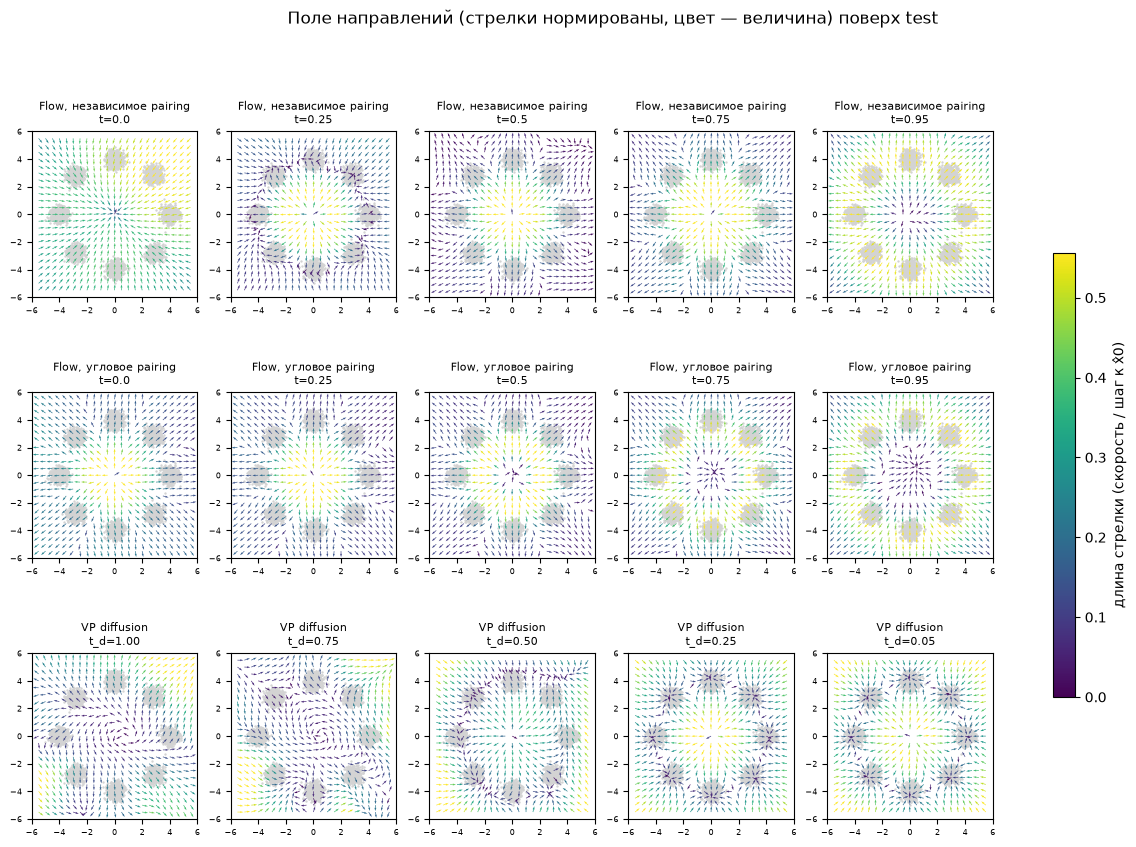

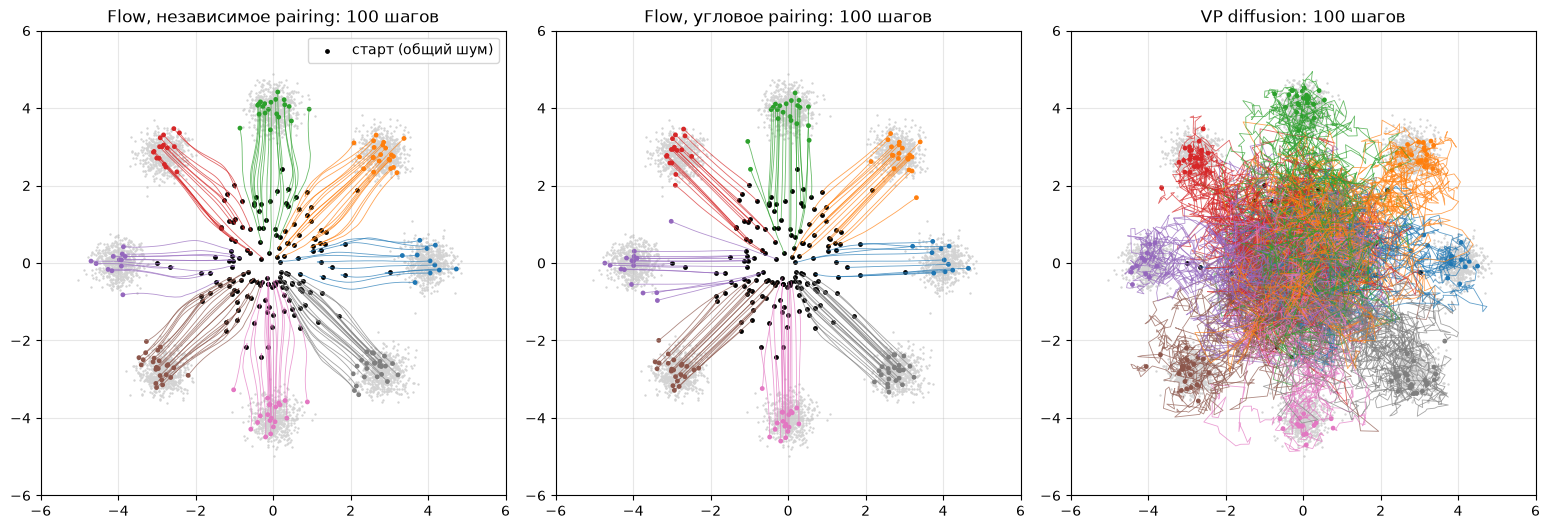

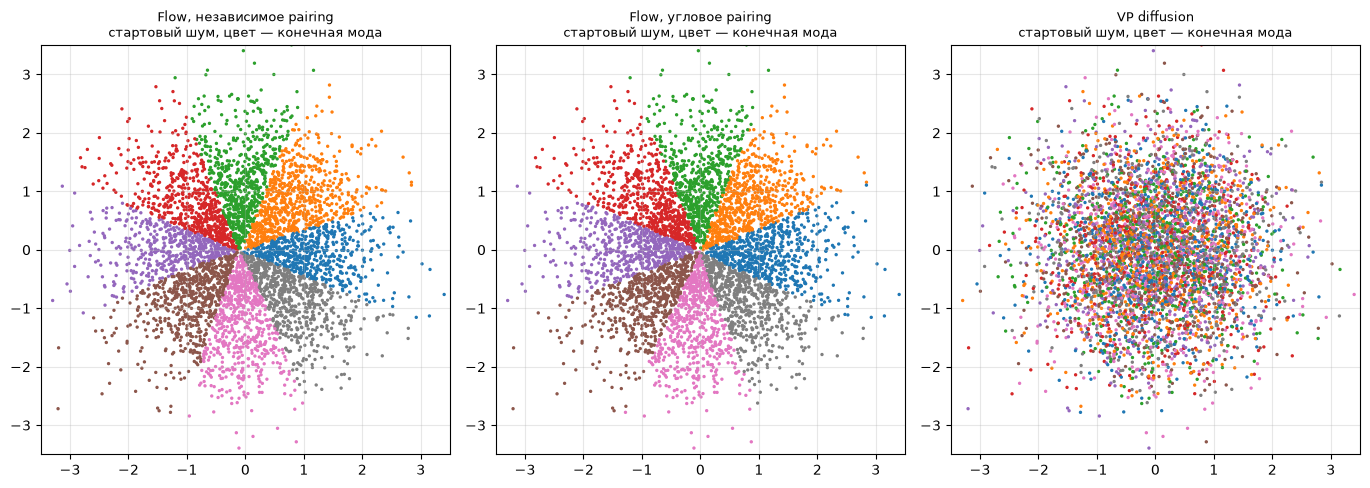

sampler,прямолинейность,длина пути,смещение,мин. радиус / старт,мода = сектор старта,в модах,SW1,та же мода при 1 шаг.,та же мода при 2 шаг.,та же мода при 5 шаг.,та же мода при 10 шаг.
flow_euler,1.063,2.890,2.722,0.939,0.905,0.931,0.125,0.586,0.878,0.967,0.989
flow_angular,1.000,2.749,2.746,1.000,0.950,0.916,0.073,0.974,0.981,0.988,0.996
vp_ancestral,8.816,36.624,4.161,0.183,0.127,0.965,0.121,0.126,0.134,0.128,0.137


sampler,t=0.0,t=0.25,t=0.5,t=0.75,t=0.95
flow_angular,0.00,0.00,0.01,0.04,0.08
flow_euler,1.00,0.59,0.02,0.00,0.00
vp_ancestral,0.08,0.60,0.55,0.59,0.60


In [12]:
# Задание 10. Поле направлений и траектории трёх sampler'ов из одного и того же исходного шума Z_COMMON.
# Стрелки: выученное поле на сетке при нескольких t. Траектории: 100 шагов из общего шума.
# Оценка точек: прямолинейность путей, связь «сектор стартового шума → мода», согласие малого числа шагов со 100.
from matplotlib.colors import Normalize

TRAJ_STEPS = 100
N_TRAJ_PLOT = 150                       # сколько траекторий рисовать (метрики — по всем N_SAMPLES)
FIELD_T = [0.0, 0.25, 0.5, 0.75, 0.95]  # время flow; для diffusion берётся тот же уровень пути t_d = 1 − t
MODELS = {'flow_euler': 'Flow, независимое pairing', 'flow_angular': 'Flow, угловое pairing',
          'vp_ancestral': 'VP diffusion'}
MODE_COLORS = plt.get_cmap('tab10')(np.arange(N_MODES))

@torch.no_grad()
def field_on_grid(method, t, grid):
    """Стрелка в каждой точке сетки: скорость для flow; для diffusion — направление к оценке x̂0."""
    tt = torch.full((len(grid),), t, device=DEVICE)
    if method == 'flow_euler':
        return flow_model(grid, tt)
    if method == 'flow_angular':
        return angular_model(grid, tt)
    td = torch.full((len(grid),), max(1.0 - t, T_EPS), device=DEVICE)
    ab = vp_alpha_bar(td).reshape(-1, 1)
    eps = diffusion_model(grid, td)
    return (grid - (1 - ab).sqrt() * eps) / ab.sqrt() - grid

@torch.no_grad()
def trajectories(method, z, n):
    if method == 'flow_euler':
        return sample_flow_euler(flow_model, z, n, return_traj=True)[1]
    if method == 'flow_angular':
        return sample_flow_euler(angular_model, z, n, return_traj=True)[1]
    return sample_vp_ancestral(diffusion_model, z, n, return_traj=True)[1]

# --- 1. Поле направлений на сетке ---
g = torch.linspace(-5.5, 5.5, 23)
gx, gy = torch.meshgrid(g, g, indexing='xy')
grid = torch.stack([gx.reshape(-1), gy.reshape(-1)], 1).to(DEVICE)
fig, axes = plt.subplots(len(MODELS), len(FIELD_T), figsize=(3.1 * len(FIELD_T), 3.2 * len(MODELS)), squeeze=False)
field_stats = []
for i, (method, title) in enumerate(MODELS.items()):
    for j, t in enumerate(FIELD_T):
        v = field_on_grid(method, t, grid).cpu().numpy()
        speed = np.linalg.norm(v, axis=1)
        u = v / np.maximum(speed[:, None], 1e-8)           # длина стрелки одинакова, величина — цветом
        ax = axes[i, j]
        ax.scatter(X_test[:, 0], X_test[:, 1], s=0.5, c='lightgray')
        q = ax.quiver(grid[:, 0].cpu(), grid[:, 1].cpu(), u[:, 0], u[:, 1], speed, cmap='viridis',
                      norm=Normalize(0, np.percentile(speed, 95)), scale=28, width=0.004)
        label = f't={t}' if method != 'vp_ancestral' else f't_d={max(1 - t, T_EPS):.2f}'
        ax.set_title(f'{title}\n{label}', fontsize=8)
        ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect('equal'); ax.tick_params(labelsize=6)
        # Доля стрелок, направленных к центру (радиальная составляющая < 0) — количественная сторона картинки.
        radial = (v * grid.cpu().numpy()).sum(1) / np.maximum(np.linalg.norm(grid.cpu().numpy(), axis=1), 1e-8)
        field_stats.append({'method': method, 't_flow': t, 'mean_speed': float(speed.mean()),
                            'inward_frac': float((radial < 0).mean())})
fig.colorbar(q, ax=axes, shrink=0.6, label='длина стрелки (скорость / шаг к x̂0)')
fig.suptitle('Поле направлений (стрелки нормированы, цвет — величина) поверх test')
fig.savefig(FIG_DIR / 'vector_fields.png', dpi=110, bbox_inches='tight'); plt.show()

# --- 2. Траектории из одного и того же шума ---
TRAJ = {m: trajectories(m, Z_COMMON, TRAJ_STEPS).cpu().numpy() for m in MODELS}   # (шаги + 1, N, 2)
z_np = Z_COMMON.cpu().numpy()
start_sector = np.round(np.arctan2(z_np[:, 1], z_np[:, 0]) / (2 * np.pi / N_MODES)).astype(int) % N_MODES

fig, axes = plt.subplots(1, len(MODELS), figsize=(5.2 * len(MODELS), 5.2))
for ax, (method, title) in zip(axes, MODELS.items()):
    tr = TRAJ[method]
    end_mode, _ = assign_modes(tr[-1])
    ax.scatter(X_test[:, 0], X_test[:, 1], s=0.5, c='lightgray')
    for k in range(N_TRAJ_PLOT):
        ax.plot(tr[:, k, 0], tr[:, k, 1], lw=0.6, alpha=0.7, color=MODE_COLORS[end_mode[k]])
    ax.scatter(tr[0, :N_TRAJ_PLOT, 0], tr[0, :N_TRAJ_PLOT, 1], s=6, c='black', label='старт (общий шум)')
    ax.scatter(tr[-1, :N_TRAJ_PLOT, 0], tr[-1, :N_TRAJ_PLOT, 1], s=6, c=MODE_COLORS[end_mode[:N_TRAJ_PLOT]])
    ax.set_title(f'{title}: {TRAJ_STEPS} шагов'); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
axes[0].legend(loc='upper right')
fig.tight_layout(); fig.savefig(FIG_DIR / 'trajectories.png', dpi=120); plt.show()

# --- 3. Куда приходит каждая точка общего шума: раскраска стартовых точек по конечной моде ---
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 4.6))
for ax, (method, title) in zip(axes, MODELS.items()):
    end_mode, _ = assign_modes(TRAJ[method][-1])
    ax.scatter(z_np[:, 0], z_np[:, 1], s=2, c=MODE_COLORS[end_mode])
    ax.set_title(f'{title}\nстартовый шум, цвет — конечная мода', fontsize=9)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect('equal'); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / 'noise_to_mode.png', dpi=120); plt.show()

# --- 4. Оценка точек из одного и того же шума ---
traj_rows = []
for method in MODELS:
    tr = TRAJ[method]
    steps = np.linalg.norm(np.diff(tr, axis=0), axis=2)               # (шаги, N)
    path_len = steps.sum(0)
    displacement = np.linalg.norm(tr[-1] - tr[0], axis=1)
    end_mode, end_dist = assign_modes(tr[-1])
    # Минимальный радиус по пути: насколько точка «заходит» к центру перед уходом в моду.
    min_radius = np.linalg.norm(tr, axis=2).min(0)
    row = {'method': method, 'traj_steps': TRAJ_STEPS,
           'straightness': float(np.median(path_len / np.maximum(displacement, 1e-8))),   # 1 — прямая
           'mean_path_length': float(path_len.mean()), 'mean_displacement': float(displacement.mean()),
           'min_radius_over_start': float(np.median(min_radius / np.maximum(np.linalg.norm(z_np, axis=1), 1e-8))),
           'end_mode_equals_start_sector': float((end_mode == start_sector).mean()),       # 1/8 = случайно
           **{k: v for k, v in sample_quality(tr[-1]).items() if k != 'mode_counts'}}
    # Согласие сэмплов с малым числом шагов (задания 7, 9 — тот же Z_COMMON) с 100-шаговым результатом.
    for n in STEP_GRID:
        if (method, n) in SAMPLES and n != TRAJ_STEPS:
            few = SAMPLES[(method, n)]
            few_mode, _ = assign_modes(few)
            row[f'dist_to_{TRAJ_STEPS}_at_{n}'] = float(np.linalg.norm(few - tr[-1], axis=1).mean())
            row[f'same_mode_as_{TRAJ_STEPS}_at_{n}'] = float((few_mode == end_mode).mean())
    traj_rows.append(row)

save_json('trajectory_metrics.json', {'traj_steps': TRAJ_STEPS, 'n_points': N_SAMPLES, 'noise': 'Z_COMMON',
                                      'field_t': FIELD_T, 'field_stats': field_stats, 'rows': traj_rows})
np.savez_compressed(ARTIFACTS / 'trajectories_subset.npz',
                    **{m: TRAJ[m][:, :N_TRAJ_PLOT] for m in MODELS})

traj_view = pd.DataFrame([{
    'sampler': r['method'], 'прямолинейность': r['straightness'], 'длина пути': r['mean_path_length'],
    'смещение': r['mean_displacement'], 'мин. радиус / старт': r['min_radius_over_start'],
    'мода = сектор старта': r['end_mode_equals_start_sector'], 'в модах': r['in_mode_frac'],
    'SW1': r['sliced_w1_vs_test'],
    **{f'та же мода при {n} шаг.': r.get(f'same_mode_as_{TRAJ_STEPS}_at_{n}', float('nan'))
       for n in STEP_GRID if n != TRAJ_STEPS and n <= 10}} for r in traj_rows])
show_table(traj_view, f'Траектории из общего шума ({N_SAMPLES} точек, {TRAJ_STEPS} шагов)',
           formats={c: '{:.3f}' for c in traj_view.columns if c != 'sampler'},
           best_min=('прямолинейность', 'длина пути', 'SW1'), best_max=('в модах',))
field_view = pd.DataFrame(field_stats).pivot(index='method', columns='t_flow', values='inward_frac').reset_index()
field_view.columns = ['sampler'] + [f't={t}' for t in FIELD_T]
show_table(field_view, 'Доля стрелок поля, направленных к центру (по сетке 23 × 23)',
           formats={c: '{:.2f}' for c in field_view.columns if c != 'sampler'})

### Задание 11. Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

#### Гипотеза (сформулирована до запуска)

**Фактор.** Свежий шум в обратном шаге VP diffusion: η = 1 (ancestral, задание 6) → η = 0 (детерминированный DDIM). Всё остальное фиксировано: та же обученная diffusion-модель, тот же общий шум (`Z_COMMON` и два набора из задания 8), та же сетка t, то же число вызовов сети (NFE) и тот же клип x̂0. Значение η = 0 выбрано заранее, test используется только для измерения.

**Предметное обоснование.** При ancestral-шаге к точке на каждом шаге подмешивается новый шум, и пока в ней мало сигнала, эти добавки перебрасывают её между секторами (см. пояснение под заданием 3). Без свежего шума обратный процесс — это детерминированное ODE, как у flow, и его отображение «шум → данные» должно сохранять сектор стартового шума.

**H1.** При η = 0 конечная мода определяется сектором стартового шума: доля «мода = сектор старта» ≥ 0.8 при n ≥ 10 шагов; у ancestral она ≤ 0.25 (около случайных 1/8).

**H2.** При малом числе шагов (≤ 10) качество DDIM не хуже ancestral: доля точек в модах не ниже. Разница считается значимой, если она больше 2·std по трём наборам шума.

**Задание 11. Творческое мини-исследование**

- **Что делали**: абляция одного фактора: убрали свежий шум из обратного шага VP (ancestral η = 1 → DDIM η = 0) при той же модели, шуме, сетке t и числе вызовов сети; 3 набора шума.
- **Зачем**: проверить, что случайность конечной моды у diffusion создаёт сэмплер, а не модель (H1), и не теряется ли качество при малом числе шагов (H2).
- **Результат**: `bonus_ddim.json`, `bonus_ddim_repeats.csv`, `figures/bonus_ddim.png`. H1 подтверждена: мода = сектор старта при n ≥ 10 — DDIM 0.807, ancestral 0.131; прямолинейность 1.05 против 8.82. H2 подтверждена частично: при 5 шагах DDIM 0.820 в модах против 0.784, но SW1 хуже; при 100 шагах TV 0.073 против 0.043.

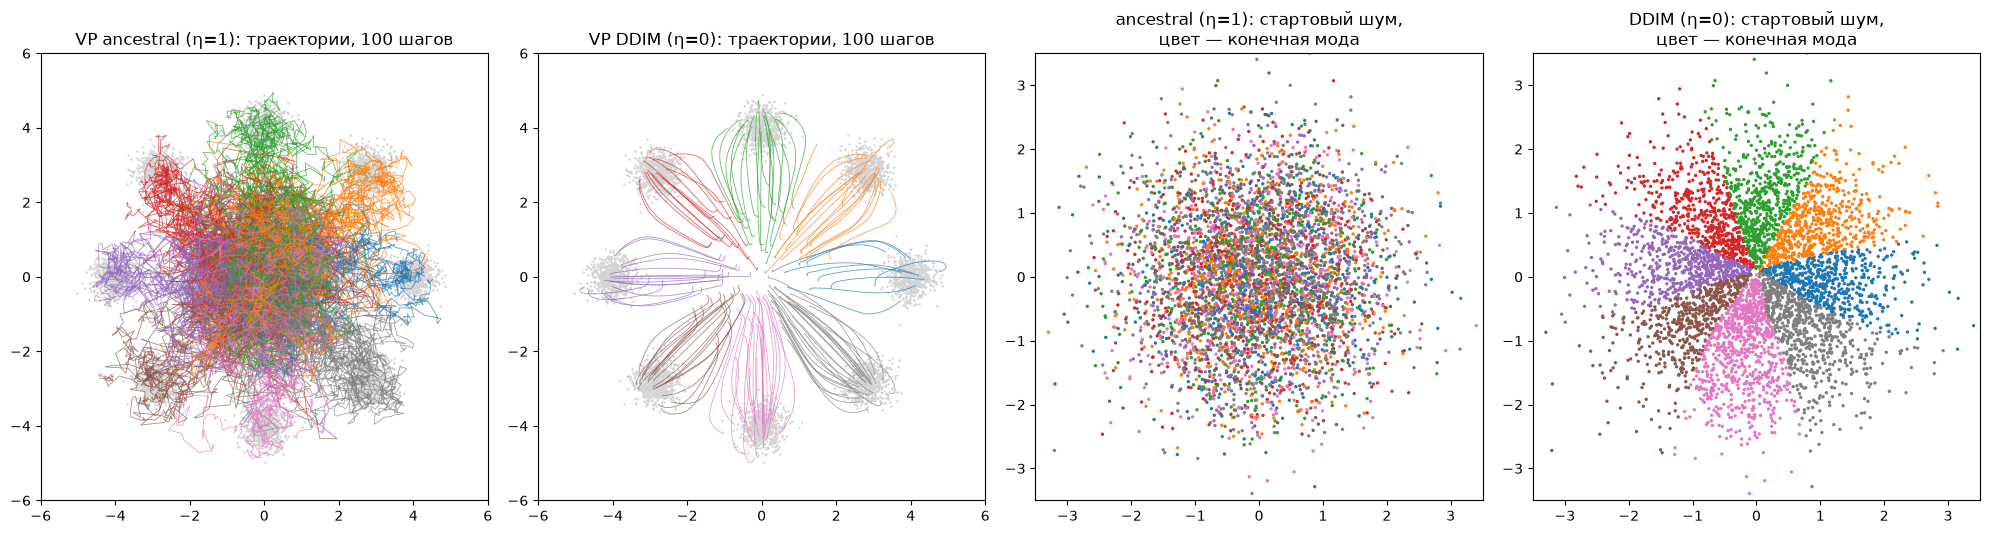

sampler,шагов,мода = сектор старта,мод покрыто,в модах,TV мод,SW1,MMD,std в моде,"время, с"
vp_ancestral (η=1),1,0.128 ± 0.005,0.0,0.045 ± 0.002,0.945,2.6812 ± 0.0365,0.37957,0.426,0.081
vp_ddim (η=0),1,0.129 ± 0.005,0.0,0.045 ± 0.002,0.945,2.6836 ± 0.0364,0.37937,0.424,0.002
vp_ancestral (η=1),2,0.120 ± 0.006,3.7,0.262 ± 0.005,0.729,0.9423 ± 0.0181,0.27907,0.370,0.003
vp_ddim (η=0),2,0.203 ± 0.010,4.0,0.270 ± 0.005,0.721,0.9066 ± 0.0143,0.26001,0.391,0.003
vp_ancestral (η=1),5,0.131 ± 0.005,8.0,0.784 ± 0.005,0.207,0.2982 ± 0.0023,0.03166,0.261,0.008
vp_ddim (η=0),5,0.624 ± 0.004,8.0,0.820 ± 0.004,0.211,0.3775 ± 0.0167,0.03902,0.266,0.006
vp_ancestral (η=1),10,0.132 ± 0.002,8.0,0.916 ± 0.007,0.089,0.1811 ± 0.0014,0.01434,0.245,0.016
vp_ddim (η=0),10,0.757 ± 0.002,8.0,0.910 ± 0.006,0.120,0.2483 ± 0.0130,0.02037,0.260,0.013
vp_ancestral (η=1),20,0.135 ± 0.005,8.0,0.955 ± 0.001,0.059,0.1732 ± 0.0041,0.01181,0.257,0.032
vp_ddim (η=0),20,0.804 ± 0.007,8.0,0.935 ± 0.005,0.087,0.2029 ± 0.0147,0.01500,0.278,0.026


шагов,diff_in_mode (ddim − ancestral),diff_sw1 (ddim − ancestral),разница > 2·std
1,-0.000,+0.0024,False
2,+0.008,-0.0356,False
5,+0.036,+0.0792,True
10,-0.006,+0.0673,False
20,-0.020,+0.0296,True
50,-0.027,+0.0098,True
100,-0.027,+0.0527,True


H1 (мода = сектор старта, n ≥ 10): ancestral 0.131, DDIM 0.807 -> подтверждена
Прямолинейность траекторий (100 шагов, медиана, 1 = прямая): {'vp_ancestral (η=1)': 8.816414833068848, 'vp_ddim (η=0)': 1.0524110794067383}


In [13]:
# Задание 11 (бонус). Абляция одного фактора: свежий шум в обратном шаге VP.
# Та же обученная diffusion-модель, тот же общий шум (Z_COMMON + два набора из задания 8), та же сетка t
# и то же число вызовов сети. Меняется только η: 1 — ancestral (задание 6), 0 — детерминированный DDIM.
# Настройка η = 0 задана до эксперимента; test используется только для измерения, не для выбора.

@torch.no_grad()
def sample_vp_ddim(model, z, n_steps, clip=True, return_traj=False):
    """Детерминированный обратный шаг VP (DDIM, η = 0): x_s = √ᾱ_s·x̂0 + √(1 − ᾱ_s)·ε̂, без нового шума.
    Сетка и клип x̂0 те же, что в sample_vp_ancestral; t = 0 не используется."""
    ts = torch.linspace(1.0, T_EPS, n_steps + 1)
    x = z.clone()
    traj = [x.clone()]
    for i in range(n_steps):
        t, s = ts[i], ts[i + 1]
        ab_t, ab_s = vp_alpha_bar(t), vp_alpha_bar(s)
        eps = model(x, torch.full((len(x),), float(t), device=x.device))
        x0_hat = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        if clip:
            x0_hat = x0_hat.clamp(-X0_CLIP, X0_CLIP)
            eps = (x - ab_t.sqrt() * x0_hat) / (1 - ab_t).sqrt()   # ε, согласованный с обрезанным x̂0
        x = ab_s.sqrt() * x0_hat + (1 - ab_s).sqrt() * eps
        if return_traj:
            traj.append(x.clone())
    return (x, torch.stack(traj)) if return_traj else x

def sector_of(points):
    points = np.asarray(points)
    return np.round(np.arctan2(points[:, 1], points[:, 0]) / (2 * np.pi / N_MODES)).astype(int) % N_MODES

BONUS_SAMPLERS = {'vp_ancestral (η=1)': lambda z, n: sample_vp_ancestral(diffusion_model, z, n),
                  'vp_ddim (η=0)': lambda z, n: sample_vp_ddim(diffusion_model, z, n)}
noise_sets = {'Z_COMMON': Z_COMMON}
for seed in EXTRA_NOISE_SEEDS:
    noise_sets[f'seed_{seed}'] = torch.randn(N_SAMPLES, 2, generator=torch.Generator().manual_seed(seed)).to(DEVICE)

bonus_rows = []
for noise_name, z in noise_sets.items():
    z_sector = sector_of(z.cpu().numpy())
    for name, sampler in BONUS_SAMPLERS.items():
        for n in STEP_GRID:
            sync(); t0 = time.perf_counter()
            pts = sampler(z, n).cpu().numpy()
            sync(); elapsed = time.perf_counter() - t0
            end_mode, _ = assign_modes(pts)
            q = sample_quality(pts)
            bonus_rows.append({'sampler': name, 'n_steps': n, 'noise': noise_name, 'sampling_time_s': elapsed,
                               'mode_equals_start_sector': float((end_mode == z_sector).mean()),
                               **{k: v for k, v in q.items() if k != 'mode_counts'}})
bonus = pd.DataFrame(bonus_rows)
bonus.to_csv(ARTIFACTS / 'bonus_ddim_repeats.csv', index=False)

B_METRICS = ['mode_equals_start_sector', 'modes_covered', 'in_mode_frac', 'mode_tv_vs_test',
             'sliced_w1_vs_test', 'mmd_vs_test', 'in_mode_std_mean', 'sampling_time_s']
bagg = bonus.groupby(['sampler', 'n_steps'])[B_METRICS].agg(['mean', 'std'])
bagg.columns = [f'{m}_{s}' for m, s in bagg.columns]
bagg = bagg.reset_index()

# Траектории из одного и того же шума: 100 шагов, первые 150 точек Z_COMMON.
_, ddim_traj = sample_vp_ddim(diffusion_model, Z_COMMON, TRAJ_STEPS, return_traj=True)
ddim_traj = ddim_traj.cpu().numpy()
anc_traj = TRAJ['vp_ancestral']
def straightness(tr):
    path = np.linalg.norm(np.diff(tr, axis=0), axis=2).sum(0)
    return float(np.median(path / np.maximum(np.linalg.norm(tr[-1] - tr[0], axis=1), 1e-8)))
traj_compare = {'vp_ancestral (η=1)': straightness(anc_traj), 'vp_ddim (η=0)': straightness(ddim_traj)}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (title, tr) in zip(axes[:2], [('VP ancestral (η=1)', anc_traj), ('VP DDIM (η=0)', ddim_traj)]):
    end_mode, _ = assign_modes(tr[-1])
    ax.scatter(X_test[:, 0], X_test[:, 1], s=0.5, c='lightgray')
    for k in range(N_TRAJ_PLOT):
        ax.plot(tr[:, k, 0], tr[:, k, 1], lw=0.6, alpha=0.7, color=MODE_COLORS[end_mode[k]])
    ax.set_title(f'{title}: траектории, {TRAJ_STEPS} шагов'); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect('equal')
for ax, (title, tr) in zip(axes[2:], [('ancestral (η=1)', anc_traj), ('DDIM (η=0)', ddim_traj)]):
    end_mode, _ = assign_modes(tr[-1])
    ax.scatter(z_np[:, 0], z_np[:, 1], s=2, c=MODE_COLORS[end_mode])
    ax.set_title(f'{title}: стартовый шум,\nцвет — конечная мода'); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
    ax.set_aspect('equal')
fig.tight_layout(); fig.savefig(FIG_DIR / 'bonus_ddim.png', dpi=110); plt.show()

# Проверка гипотезы по заранее заданным критериям (на достаточном числе шагов, n ≥ 10).
big = bagg[bagg['n_steps'] >= min(10, max(STEP_GRID))]
def mean_of(sampler, col, frame=big):
    return float(frame[frame['sampler'] == sampler][col].mean())
h1 = {'ancestral': mean_of('vp_ancestral (η=1)', 'mode_equals_start_sector_mean'),
      'ddim': mean_of('vp_ddim (η=0)', 'mode_equals_start_sector_mean')}
h1['supported'] = h1['ddim'] >= 0.8 and h1['ancestral'] <= 0.25
h2_rows = []
for n in STEP_GRID:
    a = bagg[(bagg['sampler'] == 'vp_ancestral (η=1)') & (bagg['n_steps'] == n)].iloc[0]
    d = bagg[(bagg['sampler'] == 'vp_ddim (η=0)') & (bagg['n_steps'] == n)].iloc[0]
    diff = d['in_mode_frac_mean'] - a['in_mode_frac_mean']
    noise_level = 2 * max(a['in_mode_frac_std'], d['in_mode_frac_std'], 1e-3)
    h2_rows.append({'n_steps': n, 'diff_in_mode (ddim − ancestral)': float(diff),
                    'diff_sw1 (ddim − ancestral)': float(d['sliced_w1_vs_test_mean'] - a['sliced_w1_vs_test_mean']),
                    'beyond_2std': bool(abs(diff) > noise_level)})
save_json('bonus_ddim.json', {
    'hypothesis': {'H1': 'без свежего шума конечная мода определяется сектором стартового шума (доля ≥ 0.8 при n ≥ 10; '
                         'у ancestral ≤ 0.25, т.е. около случайных 1/8)',
                   'H2': 'при малом числе шагов (≤ 10) качество DDIM не хуже ancestral: доля в модах не ниже, '
                         'разница вне 2·std повторов считается значимой'},
    'factor': 'η в обратном шаге VP: 1 → 0', 'fixed': 'модель, шум, сетка t, NFE, клип x̂0',
    'noise_sets': list(noise_sets), 'rows': bagg.to_dict(orient='records'), 'straightness_100': traj_compare,
    'H1_result': h1, 'H2_result': h2_rows})

def pm(mean, std, fmt):
    return f'{mean:{fmt}} ± {std:{fmt}}'
bview = pd.DataFrame({
    'sampler': bagg['sampler'], 'шагов': bagg['n_steps'],
    'мода = сектор старта': [pm(m, s, '.3f') for m, s in zip(bagg['mode_equals_start_sector_mean'], bagg['mode_equals_start_sector_std'])],
    'мод покрыто': bagg['modes_covered_mean'],
    'в модах': [pm(m, s, '.3f') for m, s in zip(bagg['in_mode_frac_mean'], bagg['in_mode_frac_std'])],
    'TV мод': bagg['mode_tv_vs_test_mean'],
    'SW1': [pm(m, s, '.4f') for m, s in zip(bagg['sliced_w1_vs_test_mean'], bagg['sliced_w1_vs_test_std'])],
    'MMD': bagg['mmd_vs_test_mean'], 'std в моде': bagg['in_mode_std_mean_mean'], 'время, с': bagg['sampling_time_s_mean']})
bview = bview.sort_values(['шагов', 'sampler']).reset_index(drop=True)
show_table(bview, f'Абляция η: ancestral vs DDIM (среднее ± std по {len(noise_sets)} наборам шума, n = {N_SAMPLES})',
           formats={'мод покрыто': '{:.1f}', 'TV мод': '{:.3f}', 'MMD': '{:.5f}', 'std в моде': '{:.3f}', 'время, с': '{:.3f}'})
show_table(pd.DataFrame(h2_rows).rename(columns={'n_steps': 'шагов', 'beyond_2std': 'разница > 2·std'}),
           'H2: разница DDIM − ancestral по доле точек в модах и SW1',
           formats={'diff_in_mode (ddim − ancestral)': '{:+.3f}', 'diff_sw1 (ddim − ancestral)': '{:+.4f}'})
print(f"H1 (мода = сектор старта, n ≥ 10): ancestral {h1['ancestral']:.3f}, DDIM {h1['ddim']:.3f} -> "
      f"{'подтверждена' if h1['supported'] else 'не подтверждена'}")
print(f'Прямолинейность траекторий (100 шагов, медиана, 1 = прямая): {traj_compare}')

**Ancestral vs DDIM: алгоритм.** Сеть одна (diffusion из задания 4), шаги 1–2 одинаковые; различается только сборка новой точки.

```
x  = Z_COMMON (стартовый шум),  ts = linspace(1, 0.001, n + 1)
для каждого шага t → s:
    1. ε̂  = сеть(x, t)                              # какой шум в точке?
    2. x̂0 = (x − √(1−ᾱ_t)·ε̂) / √ᾱ_t                  # где была бы чистая точка?
    3. ancestral: x = a·x̂0 + b·x + σ·randn          # сдвиг к x̂0 + НОВЫЙ случайный шум (кроме последнего шага)
       DDIM:      x = √ᾱ_s·x̂0 + √(1−ᾱ_s)·ε̂         # чистая часть + СВОЙ шум точки, уменьшенный
    → новая точка уровня s подаётся в сеть на следующем шаге
```

| | Ancestral (η = 1) | DDIM (η = 0) |
|---|---|---|
| Доля шума в новой точке | по расписанию VP | та же |
| Откуда шум | часть старого + новый случайный | только старый (`ε̂`) |
| Из одной стартовой точки | разные результаты при разном seed | всегда один результат |
| Траектория | дрожащая | гладкая |
| От чего зависит мода | от случайных добавок на шагах | от сектора стартового шума |

#### Интерпретация (полный прогон: 3000 шагов обучения, 5000 точек, 3 набора шума)

| шагов | мода = сектор старта: ancestral / DDIM | в модах: ancestral / DDIM | SW1: ancestral / DDIM | TV мод: ancestral / DDIM |
|---|---|---|---|---|
| 1 | 0.128 / 0.129 | 0.045 / 0.045 | 2.68 / 2.68 | 0.945 / 0.946 |
| 2 | 0.120 / 0.203 | 0.262 / 0.270 | 0.94 / 0.91 | 0.729 / 0.721 |
| 5 | 0.131 / **0.624** | 0.784 / **0.820** | **0.30** / 0.38 | 0.207 / 0.211 |
| 10 | 0.132 / **0.758** | 0.917 / 0.910 | **0.18** / 0.25 | **0.089** / 0.120 |
| 20 | 0.135 / **0.804** | **0.955** / 0.935 | **0.17** / 0.20 | **0.059** / 0.087 |
| 100 | 0.129 / **0.837** | **0.966** / 0.939 | **0.12** / 0.17 | **0.043** / 0.073 |

Эталон train vs test: в модах ≈ 0.99. Разброс по трём наборам шума: std ≤ 0.01 для «мода = сектор» и «в модах», ≤ 0.04 для SW1.

- **H1 подтверждена.** При n ≥ 10 доля «мода = сектор старта» у DDIM в среднем 0.81 (0.76 → 0.84 с ростом шагов), у ancestral 0.13 ≈ 1/8 при любом числе шагов. Случайность конечной моды у ancestral создаёт свежий шум на шагах, а не модель: без него та же сеть задаёт почти детерминированный «пирог» секторов, как flow. Прямолинейность траекторий (100 шагов, медиана): DDIM 1.05, ancestral 8.82 — пути DDIM почти прямые, ancestral блуждают.
- **Почему не 1.0.** На идеальном поле DDIM даёт ровно 1.000, здесь — 0.84. Обученная сеть ошибается сильнее всего при большом шуме около центра, где поле почти нулевое: малые ошибки там поворачивают точку в соседний сектор. С ростом числа шагов доля растёт (0.62 → 0.84), то есть часть потерь — ошибка дискретизации Euler-подобного шага.
- **H2 подтверждена частично.** При 5 шагах DDIM действительно кладёт в моды больше точек (0.820 против 0.784, разница больше 2·std). Но распределение в целом у него хуже уже начиная с 5 шагов: SW1 выше на 0.07–0.08, а при n ≥ 20 доля «в модах» тоже ниже (0.935–0.939 против 0.955–0.966, разница значима).
- **Объяснение расхождения.** Свежий шум ancestral работает как коррекция: ошибку поля на одном шаге частично «стирают» следующие случайные шаги. Детерминированный DDIM переносит ошибку модели до конца. Самый заметный эффект — пропорции мод: TV у DDIM почти вдвое выше при 100 шагах (0.073 против 0.043). Доли мод у DDIM задаются размерами секторов, которые нарисовала сеть, и если границы секторов неточные, одни моды получают больше точек, чем другие. У ancestral мода разыгрывается заново, и такие перекосы усредняются. Разброс внутри мод одинаков (std в моде ≈ 0.29 у обоих при 100 шагах), DDIM моды не сжимает.
- **Вывод.** Убрав свежий шум, мы сделали diffusion детерминированной (H1), но ценой точности распределения: при достаточном числе шагов ancestral ближе к test по всем метрикам. DDIM выигрывает только в узком режиме около 5 шагов по доле точек в модах.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

**Анализ результатов**

- **Что делали**: свели все конфигурации в одну таблицу (метрики + время) и автоматически нашли неудачные примеры с диагностикой: откуда стартовали провалившиеся точки.
- **Зачем**: сопоставить методы при одинаковых данных, seed и бюджете и объяснить ошибки, а не только перечислить метрики.
- **Результат**: `final_table.csv`, `failures.json`, `figures/failures.png`, `figures/failures_start_noise.png`. 7 неудачных случаев: коллапс flow за 1 шаг (100%), выброс VP на клип за 1 шаг (37.2%), перекос мод VP за 2 шага (74.4% вне мод), точки между модами у flow (6.9%) и углового flow (8.4%), смена моды flow 2 → 100 шагов (12.2%), DDIM не в своём секторе (16.5%).

sampler,шагов,мод покрыто,в модах,TV мод,SW1,MMD,радиус,std в моде,"генерация, с","обучение, с"
train_reference,0,8,0.990,0.014,0.0494,0.00244,4.009,0.294,0.000,—
flow_angular,1,8,0.762,0.229,0.1443,0.03250,3.893,0.270,0.001,9.9
flow_euler,1,0,0.000,0.990,2.3070,2.72845,0.398,—,0.001,9.0
vp_ancestral,1,0,0.046,0.944,2.7030,0.38169,7.025,0.431,0.002,9.6
vp_ddim,1,0,0.046,0.944,2.7054,0.38146,7.029,0.430,0.002,9.6
flow_angular,2,8,0.828,0.162,0.1103,0.01847,3.917,0.268,0.002,9.9
flow_euler,2,8,0.338,0.653,0.6641,0.20140,3.042,0.300,0.003,9.0
vp_ancestral,2,3,0.256,0.735,0.9483,0.28205,3.079,0.363,0.003,9.6
vp_ddim,2,4,0.265,0.725,0.9210,0.26275,3.310,0.392,0.003,9.6
flow_angular,5,8,0.887,0.103,0.0851,0.00937,3.952,0.277,0.007,9.9


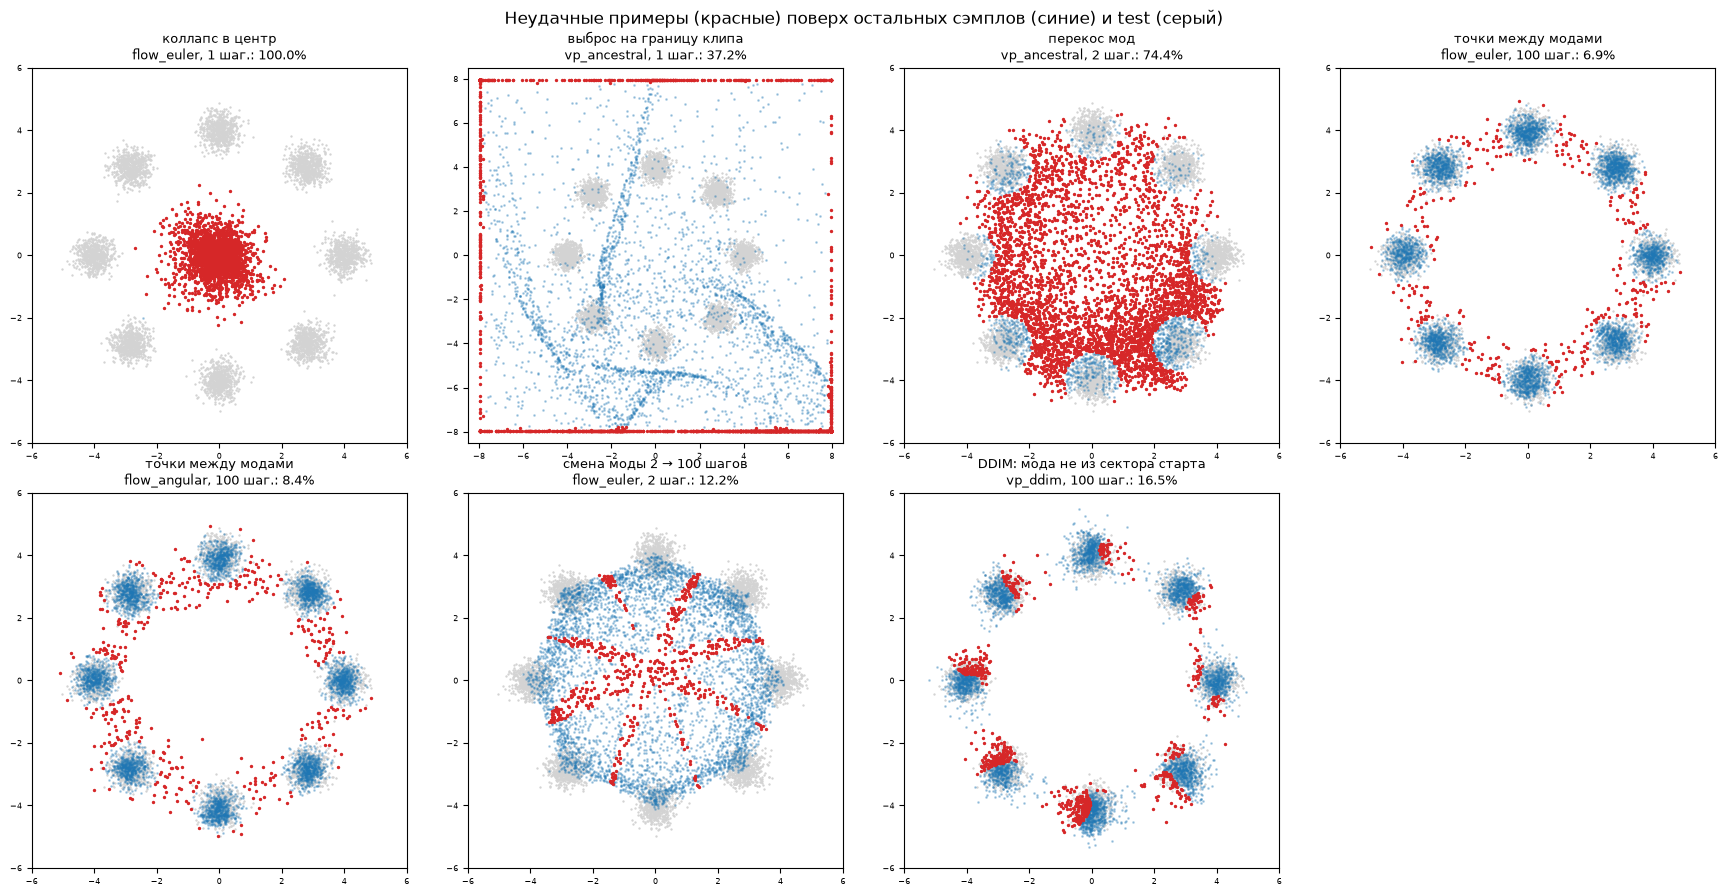

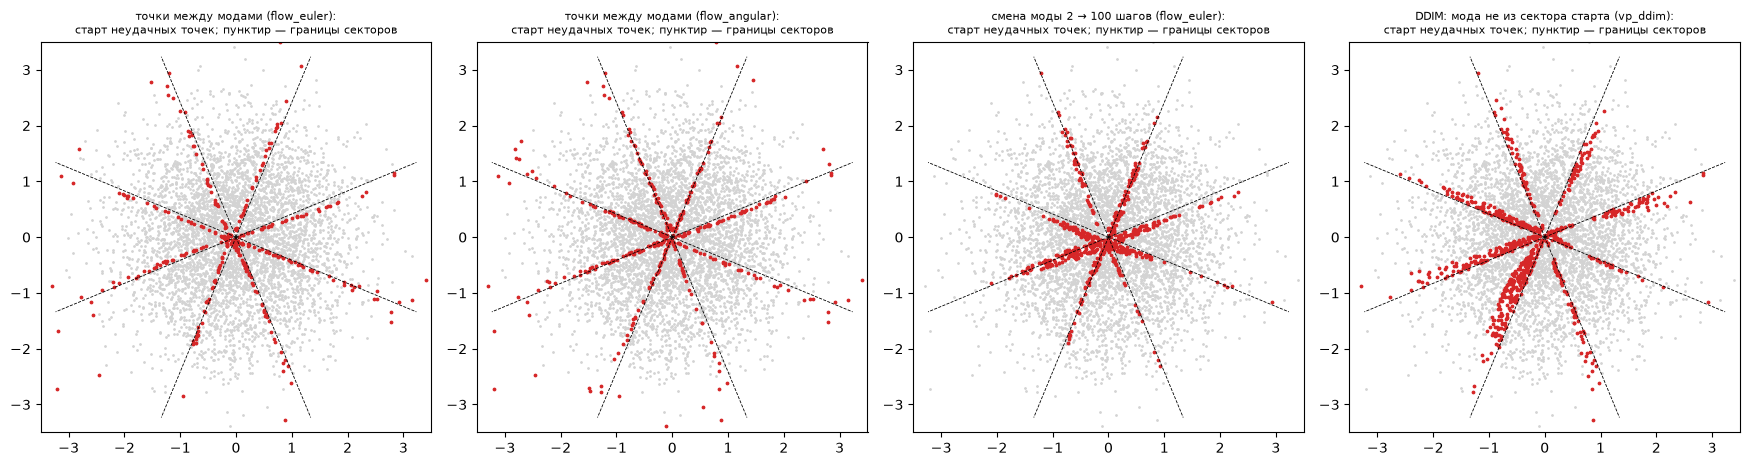

случай,sampler,шагов,доля,"угол старта от моды, °","то же у всех, °",радиус старта,то же у всех
коллапс в центр,flow_euler,1,1.000,11.3,11.3,1.19,1.19
выброс на границу клипа,vp_ancestral,1,0.372,11.6,11.3,1.82,1.19
перекос мод,vp_ancestral,2,0.744,11.3,11.3,1.10,1.19
точки между модами,flow_euler,100,0.069,18.8,11.3,0.99,1.19
точки между модами,flow_angular,100,0.084,20.1,11.3,0.86,1.19
смена моды 2 → 100 шагов,flow_euler,2,0.122,17.6,11.3,0.62,1.19
DDIM: мода не из сектора старта,vp_ddim,100,0.165,18.6,11.3,1.03,1.19


• коллапс в центр (flow_euler, 1 шаг.): 100.0% — один шаг Euler по полю при t = 0, где v(x, 0) ≈ −x: все точки сжимаются к центру
• выброс на границу клипа (vp_ancestral, 1 шаг.): 37.2% — один шаг из t = 1: x̂0 делится на √ᾱ(1) ≈ 0.0066, ошибка ε̂ усиливается в ~150 раз и упирается в клип
• перекос мод (vp_ancestral, 2 шаг.): 74.4% — два шага: первый почти целиком свежий шум, второй сразу x̂0 — моды заполнены неравномерно
• точки между модами (flow_euler, 100 шаг.): 6.9% — стартовый шум у границы секторов: поле там неоднозначно, и точка останавливается между модами
• точки между модами (flow_angular, 100 шаг.): 8.4% — стартовый шум у границы секторов: поле там неоднозначно, и точка останавливается между модами
• смена моды 2 → 100 шагов (flow_euler, 2 шаг.): 12.2% — крупный шаг у центра, где поле меняет направление, уводит точку в соседний сектор
• DDIM: мода не из сектора старта (vp_ddim, 100 шаг.): 16.5% — ошибки обученного поля около центра поворачивают детерминированную траекторию 

In [14]:
# Анализ результатов: все конфигурации при одних данных, seed, бюджете обучения и общем шуме Z_COMMON.
# 1) итоговая таблица метрик и времени; 2) неудачные примеры — находятся автоматически по сэмплам, с диагностикой причин.
ANALYSIS_STEPS = [n for n in [1, 2, 5, 10, 100] if n in STEP_GRID]
TRAIN_TIME = {'flow_euler': train_time['flow_s'], 'flow_angular': angular_time,
              'vp_ancestral': train_time['diffusion_s'], 'vp_ddim': train_time['diffusion_s']}

rows = [dict(r) for r in SAMPLE_ROWS if r['method'] in ('flow_euler', 'flow_angular', 'vp_ancestral')]
if 'bonus' in globals():   # бонус (задание 11) не обязателен для Run All
    for r in bonus[bonus['noise'] == 'Z_COMMON'].to_dict(orient='records'):
        if r['sampler'].startswith('vp_ddim'):
            rows.append({**r, 'method': 'vp_ddim'})
final = pd.DataFrame(rows)
final = final[final['n_steps'].isin(ANALYSIS_STEPS)].copy()
final['train_time_s'] = final['method'].map(TRAIN_TIME)
final = final.sort_values(['n_steps', 'method'])[['method', 'n_steps', 'modes_covered', 'in_mode_frac', 'mode_tv_vs_test',
                                                 'sliced_w1_vs_test', 'mmd_vs_test', 'mean_radius', 'in_mode_std_mean',
                                                 'sampling_time_s', 'train_time_s']].reset_index(drop=True)
final.to_csv(ARTIFACTS / 'final_table.csv', index=False)
ref_line = pd.DataFrame([{'method': 'train_reference', 'n_steps': 0, **{k: reference[k] for k in
                          ('modes_covered', 'in_mode_frac', 'mode_tv_vs_test', 'sliced_w1_vs_test', 'mmd_vs_test',
                           'mean_radius', 'in_mode_std_mean')}, 'sampling_time_s': 0.0, 'train_time_s': float('nan')}])
final_view = pd.concat([ref_line, final], ignore_index=True)
final_view.columns = ['sampler', 'шагов', 'мод покрыто', 'в модах', 'TV мод', 'SW1', 'MMD', 'радиус', 'std в моде',
                      'генерация, с', 'обучение, с']
show_table(final_view, f'Итоговая таблица: сэмплы из Z_COMMON против test (n = {N_SAMPLES}); бюджет обучения {N_STEPS} шагов',
           formats={'в модах': '{:.3f}', 'TV мод': '{:.3f}', 'SW1': '{:.4f}', 'MMD': '{:.5f}', 'радиус': '{:.3f}',
                    'std в моде': '{:.3f}', 'генерация, с': '{:.3f}', 'обучение, с': '{:.1f}'},
           best_max=('в модах',), best_min=('TV мод', 'SW1', 'MMD'), ref_rows=(0,))

# --- Неудачные примеры ---
z_angle = np.degrees(np.arctan2(z_np[:, 1], z_np[:, 0]))
z_off_axis = np.abs(((z_angle - 22.5) % 45) - 22.5)    # угол стартового шума от направления на ближайшую моду; 22.5° — граница секторов
z_radius = np.linalg.norm(z_np, axis=1)
n_max = max(STEP_GRID)

def off_mode(points):
    _, dist = assign_modes(points)
    return dist >= IN_MODE_RADIUS

def start_diag(mask):
    """Откуда стартовали неудачные точки: угол от направления на моду и радиус шума (медианы) против всех точек."""
    if not mask.any():
        return {}
    return {'start_off_axis_deg': float(np.median(z_off_axis[mask])), 'all_off_axis_deg': float(np.median(z_off_axis)),
            'start_radius': float(np.median(z_radius[mask])), 'all_radius': float(np.median(z_radius))}

failures = []
def add_failure(name, method, n, mask, reason, extra=None):
    pts = SAMPLES[(method, n)]
    failures.append({'case': name, 'sampler': method, 'n_steps': n, 'n_failed': int(mask.sum()),
                     'frac_failed': float(mask.mean()), 'reason': reason, **start_diag(mask), **(extra or {}),
                     '_mask': mask, '_pts': pts})

pts = SAMPLES[('flow_euler', 1)]
add_failure('коллапс в центр', 'flow_euler', 1, off_mode(pts),
            'один шаг Euler по полю при t = 0, где v(x, 0) ≈ −x: все точки сжимаются к центру',
            {'mean_radius': float(np.linalg.norm(pts, axis=1).mean())})
pts = SAMPLES[('vp_ancestral', 1)]
add_failure('выброс на границу клипа', 'vp_ancestral', 1, np.abs(pts).max(1) > 0.98 * X0_CLIP,
            'один шаг из t = 1: x̂0 делится на √ᾱ(1) ≈ 0.0066, ошибка ε̂ усиливается в ~150 раз и упирается в клип',
            {'mean_radius': float(np.linalg.norm(pts, axis=1).mean())})
if 2 in STEP_GRID:
    pts = SAMPLES[('vp_ancestral', 2)]
    modes, dist = assign_modes(pts)
    counts = np.bincount(modes[dist < IN_MODE_RADIUS], minlength=N_MODES)
    add_failure('перекос мод', 'vp_ancestral', 2, off_mode(pts),
                'два шага: первый почти целиком свежий шум, второй сразу x̂0 — моды заполнены неравномерно',
                {'mode_counts': counts.tolist(), 'max_min_ratio': float(counts.max() / max(counts.min(), 1))})
for method in ('flow_euler', 'flow_angular'):
    add_failure('точки между модами', method, n_max, off_mode(SAMPLES[(method, n_max)]),
                'стартовый шум у границы секторов: поле там неоднозначно, и точка останавливается между модами')
if 2 in STEP_GRID:
    m_few, _ = assign_modes(SAMPLES[('flow_euler', 2)])
    m_full, _ = assign_modes(SAMPLES[('flow_euler', n_max)])
    add_failure(f'смена моды 2 → {n_max} шагов', 'flow_euler', 2, m_few != m_full,
                'крупный шаг у центра, где поле меняет направление, уводит точку в соседний сектор')
if 'bonus' in globals():
    ddim_pts = sample_vp_ddim(diffusion_model, Z_COMMON, n_max).cpu().numpy()
    SAMPLES[('vp_ddim', n_max)] = ddim_pts
    m_ddim, _ = assign_modes(ddim_pts)
    add_failure('DDIM: мода не из сектора старта', 'vp_ddim', n_max, m_ddim != sector_of(z_np),
                'ошибки обученного поля около центра поворачивают детерминированную траекторию в соседний сектор')

fig, axes = plt.subplots(2, int(np.ceil(len(failures) / 2)), figsize=(4.4 * int(np.ceil(len(failures) / 2)), 9),
                         squeeze=False)
for ax, f in zip(axes.ravel(), failures):
    ax.scatter(X_test[:, 0], X_test[:, 1], s=0.5, c='lightgray')
    ax.scatter(f['_pts'][~f['_mask'], 0], f['_pts'][~f['_mask'], 1], s=1, c='tab:blue', alpha=0.3)
    ax.scatter(f['_pts'][f['_mask'], 0], f['_pts'][f['_mask'], 1], s=2, c='tab:red')
    ax.set_title(f"{f['case']}\n{f['sampler']}, {f['n_steps']} шаг.: {f['frac_failed']:.1%}", fontsize=9)
    lim = 8.5 if f['sampler'] == 'vp_ancestral' and f['n_steps'] == 1 else 6
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal'); ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(failures):]:
    ax.axis('off')
fig.suptitle('Неудачные примеры (красные) поверх остальных сэмплов (синие) и test (серый)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'failures.png', dpi=110); plt.show()

# Откуда стартовали точки «между модами» и «смена моды»: стартовый шум и границы секторов.
start_cases = [f for f in failures if f['case'].startswith(('точки между', 'смена моды', 'DDIM'))]
fig, axes = plt.subplots(1, len(start_cases), figsize=(4.4 * len(start_cases), 4.4), squeeze=False)
for ax, f in zip(axes[0], start_cases):
    ax.scatter(z_np[:, 0], z_np[:, 1], s=1, c='lightgray')
    ax.scatter(z_np[f['_mask'], 0], z_np[f['_mask'], 1], s=3, c='tab:red')
    for b in np.radians(22.5 + 45 * np.arange(N_MODES)):
        ax.plot([0, 3.5 * np.cos(b)], [0, 3.5 * np.sin(b)], color='black', lw=0.6, ls='--')
    ax.set_title(f"{f['case']} ({f['sampler']}):\nстарт неудачных точек; пунктир — границы секторов", fontsize=8)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect('equal')
fig.tight_layout(); fig.savefig(FIG_DIR / 'failures_start_noise.png', dpi=110); plt.show()

failure_table = pd.DataFrame([{k: v for k, v in f.items() if not k.startswith('_')} for f in failures])
save_json('failures.json', failure_table.to_dict(orient='records'))
show_table(failure_table[['case', 'sampler', 'n_steps', 'frac_failed', 'start_off_axis_deg', 'all_off_axis_deg',
                          'start_radius', 'all_radius']].rename(columns={
               'case': 'случай', 'n_steps': 'шагов', 'frac_failed': 'доля', 'start_off_axis_deg': 'угол старта от моды, °',
               'all_off_axis_deg': 'то же у всех, °', 'start_radius': 'радиус старта', 'all_radius': 'то же у всех'}),
           'Неудачные примеры: доля и откуда стартовали (медианы; 22.5° — граница секторов)',
           formats={'доля': '{:.3f}', 'угол старта от моды, °': '{:.1f}', 'то же у всех, °': '{:.1f}',
                    'радиус старта': '{:.2f}', 'то же у всех': '{:.2f}'})
for f in failures:
    print(f"• {f['case']} ({f['sampler']}, {f['n_steps']} шаг.): {f['frac_failed']:.1%} — {f['reason']}")

### Выводы по фактическим измерениям

Полный прогон: 3000 шагов обучения на модель, батч 512, одни и те же train-выборка, батчи и шум; 5000 сэмплов из общего шума против независимого test. Средние по трём наборам шума из задания 8 (std ≤ 0.02 для «в модах» и SW1), для углового flow — по `Z_COMMON`.

| sampler | 1 шаг: в модах / SW1 | 5 шагов | 10 шагов | 100 шагов | TV мод (100) | обучение, с |
|---|---|---|---|---|---|---|
| train vs test (эталон) | 0.990 / 0.049 | | | | 0.014 | — |
| flow, независимое pairing | 0.000 / 2.31 | 0.802 / 0.275 | 0.881 / 0.188 | 0.932 / 0.142 | 0.078 | 9.0 |
| flow, угловое pairing | **0.762 / 0.144** | **0.887 / 0.085** | 0.905 / **0.075** | 0.916 / **0.073** | 0.076 | 9.9 |
| VP ancestral | 0.045 / 2.68 | 0.784 / 0.298 | **0.916** / 0.181 | **0.965** / 0.121 | **0.043** | 9.6 |
| VP DDIM (бонус) | 0.045 / 2.68 | 0.820 / 0.377 | 0.910 / 0.248 | 0.939 / 0.174 | 0.073 | 9.6 |

Генерация 5000 точек занимает от 2 мс (1 шаг) до 0.18 с (100 шагов), ≈ 1–2 мс на вызов сети; обучение — 9–10 с на модель, бюджеты равны.

**Проверяемые выводы**

1. **Угловое pairing выпрямляет поле и сокращает число шагов.** За 1 шаг угловой flow даёт SW1 0.144 — столько же, сколько независимый flow за 100 шагов (0.142), то есть в 100 раз меньше вызовов сети при том же расстоянии до test. Причина видна в задании 9: при угловом pairing средняя длина пути 2.81 против 4.15, все пары в своём секторе (против 12%). Траектории (задание 10): прямолинейность 1.000 против 1.063, а при t = 0 к центру направлено 0% стрелок углового поля против 99.8% у независимого.
2. **По доле точек в модах и пропорциям мод лучший — VP ancestral при ≥ 20 шагах:** 0.965 в модах и TV 0.043 при 100 шагах. Это единственный sampler, достигший цели задания 8 (≥ 0.95 в модах, 8/8 мод) — с 20 шагов. Flow (0.932) и угловой flow (0.916) выходят на плато ниже цели.
3. **Угловой flow лучший по SW1/MMD, но не по доле в модах** (0.916 при 100 шагах). SW1 оценивает распределение массы целиком, а «в модах» — только точки внутри 3σ; у углового flow 8.4% точек остаются между модами (неудачный пример 5).
4. **Flow отображает шум в моды детерминированно и по сектору старта** (90.5% у независимого, 95.0% у углового), diffusion ancestral — нет (12.7% ≈ 1/8): моду у него выбирает свежий шум, а не модель (подтверждено бонусом: без свежего шума 81–84%).
5. **Ни один sampler не достиг эталона train vs test** (0.990 в модах, SW1 0.049): при бюджете 3000 шагов модели недоучены около границ секторов, где поле должно резко менять направление.

**Неудачные примеры** (таблица и `failures.png`, `failures_start_noise.png` выше; угол старта — медианный угол стартового шума от направления на ближайшую моду, 22.5° — граница секторов, у всех точек 11.3°)

1. **Flow, 1 шаг — коллапс в центр:** 100% точек вне мод, средний радиус 0.39. Поле при t = 0 равно ≈ −x (99.8% стрелок к центру), один шаг Euler длиной 1 сводит облако к нулю.
2. **VP ancestral, 1 шаг — выброс на границу клипа:** 95% вне мод, 37% точек упёрлись в клип ±7.9, средний радиус 7.0. Оценка x̂0 из чистого шума делится на √ᾱ(1) ≈ 0.0066 — ошибки ε̂ усиливаются в ~150 раз.
3. **VP ancestral, 2 шага — перекос мод:** в среднем покрыто 3.7 из 8 мод; число точек по модам от 64 до 376. Первый шаг почти целиком свежий шум (85% новой дисперсии), второй сразу берёт x̂0, который при t ≈ 0.5 ещё усреднён между модами.
4. **Flow, 100 шагов — точки между модами (6.9%):** стартовали в 18.8° от направления на моду (почти на границе секторов) и ближе к центру (радиус 0.99 против 1.19). Там поле неоднозначно, и MLP сглаживает резкий поворот — точка останавливается между двумя модами.
5. **Угловой flow, 100 шагов — точки между модами (8.4%):** тот же механизм, ещё сильнее (20.1° от моды, радиус 0.86): угловое pairing задаёт резкие границы секторов, которые MLP не может воспроизвести точно.
6. **Flow, 2 шага против 100 — смена моды (12.2%):** точки стартовали у границ секторов (17.6°) и очень близко к центру (радиус 0.62); крупный шаг около центра, где поле меняет направление, уводит их в соседний сектор.
7. **DDIM (бонус) — мода не из сектора старта (≈ 16%):** детерминированная траектория без шумовой коррекции переносит ошибки поля около центра до конца.

**Ограничения**

- Двумерная игрушечная задача с модами по кругу; угловое pairing опирается на эту симметрию и не переносится на данные без центра симметрии и на высокую размерность (там нужен OT-pairing).
- Одна инициализация и один порядок батчей на модель: разброс оценён только по стартовому шуму (3 набора), не по seed обучения.
- Бюджет 3000 шагов: выводы о плато (flow 0.93, угловой 0.92) могут измениться при более долгом обучении.
- Пороги метрик (3σ для «в модах», 25% ожидаемой доли для «покрыта») выбраны заранее и условны; SW1 зависит от 128 случайных проекций, MMD — от выбранных ширин ядра.
- Время генерации измеряется в миллисекундах и шумит; сравнивать надёжнее по числу вызовов сети.
- Клип x̂0 использует масштаб train-данных (как [−1, 1] в DDPM) — это знание о данных, недоступное в общем случае.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.

**Требования к сдаче**

- **Что делали**: собрали `run_info.json`: конфигурацию, версии библиотек, источник данных и моделей, список checkpoints, рисунков и таблиц, время прогона.
- **Зачем**: приложить к сдаче всё, что нужно для воспроизведения, и не дать сдать FAST-прогон.
- **Результат**: `run_info.json`. Python 3.12.1, torch 2.11.0+cu128, CUDA 12.8, NVIDIA GeForce RTX 3060; данные синтетические, модели свои (лицензии не нужны); 4 checkpoints, 12 рисунков, 23 файла метрик; время полного прогона 8030 с.

In [15]:
# Требования к сдаче: конфигурация, версии библиотек, источник данных и модели, checkpoints, артефакты, время прогона.
import sys, platform, matplotlib

def file_list(folder):
    return [{'path': str(p.relative_to(ARTIFACTS.parent)), 'size_kb': round(p.stat().st_size / 1024, 1)}
            for p in sorted(folder.rglob('*')) if p.is_file()]

run_info = {
    'fast_dev_run': FAST_DEV_RUN,
    'config': {'seed': SEED, 'device': DEVICE, 'n_modes': N_MODES, 'radius': RADIUS, 'mode_std': MODE_STD,
               'n_train': N_TRAIN, 'n_test': N_TEST, 'train_seed': TRAIN_SEED, 'test_seed': TEST_SEED,
               'hidden': HIDDEN, 'n_layers': N_LAYERS, 'n_freq': N_FREQ, 'n_params': int(n_params),
               'n_steps': N_STEPS, 'batch_size': BATCH_SIZE, 'lr': LR, 'beta_min': BETA_MIN, 'beta_max': BETA_MAX,
               't_eps': T_EPS, 'x0_clip': X0_CLIP, 'step_grid': STEP_GRID, 'n_samples': N_SAMPLES,
               'noise_seed': NOISE_SEED, 'ancestral_seed': ANCESTRAL_SEED},
    'versions': {'python': sys.version.split()[0], 'platform': platform.platform(), 'torch': torch.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
                 'cuda': torch.version.cuda if torch.cuda.is_available() else None,
                 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None},
    'data': {'source': 'синтетическая смесь 8 гауссиан на окружности, генерируется в задании 1 (numpy default_rng)',
             'file': str(DATA_ROOT / 'eight_modes.npz'), 'license': 'внешних данных нет — лицензия не требуется'},
    'models': {'source': 'собственный TimeMLP, обучен с нуля; предобученные веса не используются',
               'license': 'внешних моделей нет'},
    'train_time_s': {'flow': train_time['flow_s'], 'diffusion': train_time['diffusion_s'], 'flow_angular': angular_time},
    'checkpoints': file_list(CKPT_DIR),
    'figures': file_list(FIG_DIR),
    'artifacts': [f for f in file_list(ARTIFACTS) if not f['path'].startswith((str(CKPT_DIR.relative_to(ARTIFACTS.parent)),
                                                                                str(FIG_DIR.relative_to(ARTIFACTS.parent))))],
    'notebook_runtime_s': time.time() - NOTEBOOK_T0,
}
save_json('run_info.json', run_info)

show_table(pd.DataFrame([(k, str(v)) for k, v in {**run_info['versions'], 'fast_dev_run': FAST_DEV_RUN,
                                                     'время прогона, с': round(run_info['notebook_runtime_s'], 1)}.items()],
                        columns=['параметр', 'значение']), 'Окружение и версии', formats={})
show_table(pd.DataFrame(run_info['checkpoints']), 'Checkpoints', formats={'size_kb': '{:.1f}'})
show_table(pd.DataFrame(run_info['figures'] + run_info['artifacts']), 'Сохранённые изображения и таблицы',
           formats={'size_kb': '{:.1f}'})
assert not FAST_DEV_RUN, 'FAST_DEV_RUN=True — это проверка связности; для сдачи перезапустите в полном режиме'

параметр,значение
python,3.12.1
platform,Windows-11-10.0.22631-SP0
torch,2.11.0+cu128
numpy,2.5.3
pandas,3.0.5
matplotlib,3.11.2
cuda,12.8
gpu,NVIDIA GeForce RTX 3060
fast_dev_run,False
"время прогона, с",8029.6


path,size_kb
lab15\checkpoints\angular_last.pt,2432.8
lab15\checkpoints\diffusion_init.pt,797.6
lab15\checkpoints\flow_init.pt,797.5
lab15\checkpoints\train_last.pt,4850.8


path,size_kb
lab15\figures\angular_pairing.png,135.8
lab15\figures\bonus_ddim.png,769.4
lab15\figures\data_geometry.png,176.4
lab15\figures\failures.png,501.5
lab15\figures\failures_start_noise.png,212.7
lab15\figures\linear_path.png,423.8
lab15\figures\noise_to_mode.png,374.8
lab15\figures\quality_vs_steps.png,95.4
lab15\figures\samples_grid.png,524.4
lab15\figures\training_history.png,111.1
